# Which SVs are present in cold-origin founders and absent from warm-origin ones?

`sv_founder_confound.ipynb` showed cold-origin ecotypes carry more inserted sequence
(ρ = −0.54 with origin bio1). A carrier-*mean* climate per SV hides what that is made of: an
insertion carried by five Scandinavian founders and one carried by five founders scattered across
Europe can have the same mean. This notebook counts carriers **per climate group** instead.

**Founder groups.** The 231 founders are split into tertiles of origin bio1: **cold ≤ 8.3 °C**,
**temperate 8.3–10.7 °C**, **warm ≥ 10.7 °C**, 77 each.

**SVs.** Records with a net length change > 50 bp: *insertion* = ALT longer than REF (sequence absent
from TAIR10/Col-0), *deletion* = REF longer. Many records are complex replacements (both alleles
long), classed by net length.

**The unit is the Truvari event, not the record.** arch3 is the biallelic ("allele") representation of
a multi-allelic PanGenie graph VCF, so one event appears once per *distinct* inserted sequence — up
to one per assembly in the graph. `_build_event_map.py` collapses alleles of one graph bubble by
Truvari-collapse sequence/size similarity (`arch3_event_map.npz`, truvari-collapse defaults:
size and sequence similarity ≥ 0.95, ≤ 500 bp apart); carriers = union over an event's records.
**172,220 insertion records are 50,231 events; 54,248 deletion records are 39,709.** The graph bubble
alone — what an earlier version of this notebook used — is too loose (it can hold genuinely different
insertions at the same site: 27,301 insertion bubbles, well under the event count); merging on
position alone under-merges by ~1.5× (41,824 insertion "loci"); and not merging at all inflates
group-specific insertions, because one insertion's carriers get split across lineage-specific
alleles. §2c and §2d show how much of each result is that splitting.

**Floor: loci carried by only one founder are dropped throughout** (carriers ≥ 2). Singletons are
the least trustworthy layer and the one most shaped by the panel: long-read (cactus) assemblies
resolve private SVs that PanGenie genotyping cannot, and the cold tertile has more cactus founders
(32 vs 25 warm).

**Presence.** A locus is *present* in a group if it has ≥ k carriers there; k = 1, 2, 3 are shown
side by side. That gives seven Venn regions (cold-only, warm-only, cold+warm, all three, …) plus
"below k in every group".

**The null (called-founder).** "Present in cold, absent in warm" is often true by chance for rare
loci. So every count is paired with an expectation: each locus's carriers are redrawn 200 times at
random from the founders **genotyped (called) at that locus**, keeping its carrier count. Carriers
can only come from called founders, and call rates differ by panel half, so this is the fair
comparison. Draws are independent across loci, so the null intervals ignore linkage between loci.
What the null does **not** remove is population structure: cold-origin founders are largely one
clade, so "cold-specific" and "clade-specific" are not separable here — that is why deletions are
shown alongside as the structure control.

In [1]:

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({'figure.dpi':110,'font.size':8,'axes.linewidth':0.6})

G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
os.makedirs(f"{G}/plots",exist_ok=True)
def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.88",lw=0.7,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)

Z=np.load(f"{G}/sv_origin_partition_null_event.npz",allow_pickle=True)
F=pd.read_csv(f"{G}/sv_origin_partition_founders.csv",dtype={"founder":str})
V=pd.read_csv(f"{G}/sv_origin_partition_variants_event.csv")    # one row per EVENT
KS=[int(k) for k in Z["ks"]]; STRATA=[tuple(s) for s in Z["strata"]]; NDRAW=int(Z["ndraw"]); edges=Z["tertile_edges"]
MINC=2                                  # carrier floor: singleton loci dropped everywhere
KEEP=[i for i,(a,b) in enumerate(STRATA) if a>=MINC]; STRATA=[STRATA[i] for i in KEEP]
print(f"loci: {(V.type=='ins').sum():,} insertion ({int(Z['nrec_ins']):,} records), {(V.type=='del').sum():,} deletion ({int(Z['nrec_del']):,} records)")
V=V[V.n_alt>=MINC].reset_index(drop=True)
SLAB=[f"{a}" if a==b else (f"{a}-{b}" if b<10**5 else f"{a}+") for a,b in STRATA]
# pattern index: bit0 cold, bit1 temperate, bit2 warm
PAT=[1,3,2,6,4,7,5]                    # cold -> warm gradient (cold only .. warm only), then the two patterns spanning cold and warm
PX=np.array([0,1,2,3,4,5.7,6.7])        # x positions: gap before the spanning patterns
PNAME={1:"cold only",3:"cold + temperate",2:"temperate only",7:"all three",5:"cold + warm",6:"temperate + warm",4:"warm only",0:"below k everywhere"}
PCOL={1:"#2166AC",3:"#6A9BD0",2:"0.6",7:"0.35",5:"#9E7BB5",6:"#D98B7C",4:"#B2182B",0:"0.8"}
CG={"cold":"#2166AC","temperate":"0.5","warm":"#B2182B"}

print(f"founders: {F.group.value_counts().to_dict()}; tertile edges {edges[0]:.2f} / {edges[1]:.2f} C")
print(f"cactus (long-read assembly) founders per tertile: {F.groupby('group').is_cactus.sum().to_dict()}")
print(f"loci with >= {MINC} carriers: {(V.type=='ins').sum():,} insertion, {(V.type=='del').sum():,} deletion; {NDRAW} null draws")
def obs(t,k): return Z[f"obs_pat_{t}_k{k}"][KEEP]      # [strata x 8], singleton stratum dropped
def nul(t,k): return Z[f"null_pat_{t}_k{k}"][:,KEEP]   # [draws x strata x 8]


loci: 50,231 insertion (172,220 records), 39,709 deletion (54,248 records)
founders: {'temperate': 77, 'warm': 77, 'cold': 77}; tertile edges 8.27 / 10.72 C
cactus (long-read assembly) founders per tertile: {'cold': 32, 'temperate': 23, 'warm': 25}
loci with >= 2 carriers: 32,651 insertion, 26,923 deletion; 200 null draws


## 1. The Venn regions, observed against the null

Bars: observed number of loci in each region, all carrier counts ≥ 2 pooled. Marker: mean of the
200 called-founder draws (whiskers: 2.5–97.5%); the label is observed ÷ expected. The first five
regions run cold → warm (cold only, cold + temperate, temperate only, temperate + warm, warm only);
after the gap come the two patterns that span cold *and* warm (all three, cold + warm).
Insertions on top, deletions below; columns are k = 1, 2, 3. The "below k everywhere" count is in
the axis label.

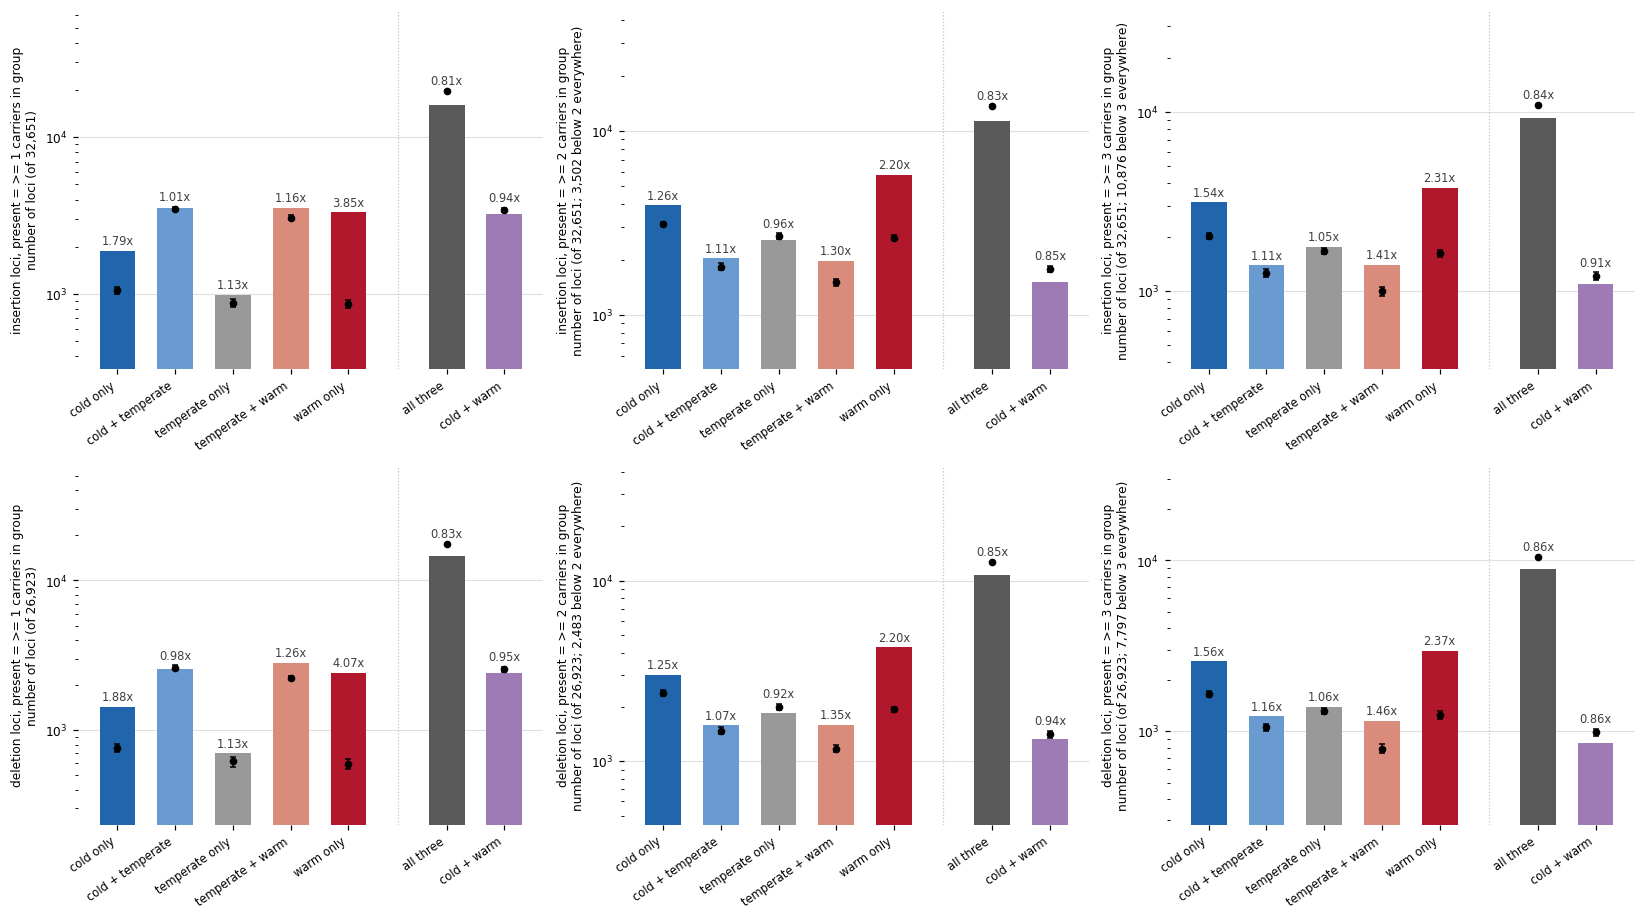


INSERTIONS -- observed / expected (called-founder null) = ratio
region                                         k=1                         k=2                         k=3
cold only                 1,882 /   1,054 =  1.79x    3,956 /   3,129 =  1.26x    3,131 /   2,036 =  1.54x
cold + temperate          3,543 /   3,494 =  1.01x    2,035 /   1,829 =  1.11x    1,396 /   1,260 =  1.11x
temperate only              991 /     874 =  1.13x    2,558 /   2,669 =  0.96x    1,765 /   1,674 =  1.05x
temperate + warm          3,557 /   3,073 =  1.16x    1,964 /   1,512 =  1.30x    1,404 /     997 =  1.41x
warm only                 3,314 /     861 =  3.85x    5,786 /   2,628 =  2.20x    3,766 /   1,630 =  2.31x
all three                16,123 /  19,838 =  0.81x   11,334 /  13,706 =  0.83x    9,216 /  10,928 =  0.84x
cold + warm               3,241 /   3,457 =  0.94x    1,516 /   1,777 =  0.85x    1,097 /   1,211 =  0.91x
below k everywhere            0 /       0            3,502 /   5,400 =  0.65x  

In [2]:

fig,ax=plt.subplots(2,3,figsize=(15,8.4),sharey=False)
for r,t in enumerate(("ins","del")):
    for c,k in enumerate(KS):
        a=ax[r,c]; style(a,axis="y")
        o=obs(t,k).sum(0); n=nul(t,k).sum(1)
        x=PX; vals=[o[p] for p in PAT]
        a.axvline(4.85,color="0.75",lw=0.8,ls=":")
        a.bar(x,vals,color=[PCOL[p] for p in PAT],width=0.62,linewidth=0)
        m=n.mean(0); lo=np.percentile(n,2.5,axis=0); hi=np.percentile(n,97.5,axis=0)
        a.errorbar(x,[m[p] for p in PAT],yerr=[[m[p]-lo[p] for p in PAT],[hi[p]-m[p] for p in PAT]],fmt="o",color="k",ms=4,capsize=2,lw=1,zorder=3)
        for xi,p in zip(x,PAT):
            if m[p]>0: a.annotate(f"{o[p]/m[p]:.2f}x",(xi,max(o[p],hi[p])),xytext=(0,4),textcoords="offset points",ha="center",fontsize=7.5,color="0.25")
        a.set_yscale("log"); a.set_ylim(max(1,min(v for v in vals if v>0)/3),max(vals)*4)
        a.set_xticks(x); a.set_xticklabels([PNAME[p] for p in PAT],rotation=35,ha="right",fontsize=7.5)
        below=f"; {o[0]:,} below {k} everywhere" if o[0]>0 else ""
        a.set_ylabel(f"{'insertion' if t=='ins' else 'deletion'} loci, present = >= {k} carriers in group\nnumber of loci (of {o.sum():,}{below})")
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_origin_partition_regions.png",dpi=130,bbox_inches="tight"); plt.show()

for t in ("ins","del"):
    print(f"\n{'INSERTIONS' if t=='ins' else 'DELETIONS'} -- observed / expected (called-founder null) = ratio")
    print(f"{'region':<22}"+"".join(f"{'k='+str(k):>28}" for k in KS))
    for p in PAT+[0]:
        line=f"{PNAME[p]:<22}"
        for k in KS:
            o=obs(t,k).sum(0)[p]; m=nul(t,k).sum(1).mean(0)[p]
            line+=f"{o:>9,} /{m:>8,.0f} = {o/m:>5.2f}x" if m>0 else f"{o:>9,} /{m:>8,.0f}        "
        print(line)
print("\ncold-only ratio / warm-only ratio (> 1: cold-skewed)")
for t in ("ins","del"):
    rr=[]
    for k in KS:
        o=obs(t,k).sum(0); m=nul(t,k).sum(1).mean(0); rr.append((o[1]/m[1])/(o[4]/m[4]))
    print(f"  {t}: "+"  ".join(f"k={k} {v:.2f}" for k,v in zip(KS,rr)))


## 2. Per-founder SV load against origin climate

The founder-level scatter in `sv_founder_confound.ipynb` (ρ = −0.54) counts only **common,
well-called** insertion records: MAC ≥ 12 and call rate ≥ 0.9 (3,258 records). The first three
panels redo that scatter on three insertion sets, from the scatter's filter to every insertion
**allele (record) carried by ≥ 2 founders**. Here the floor is applied per allele, not per locus: a
founder carries at most one record per locus, so totals are not double counted, and the per-allele
floor also removes *private alleles of shared loci* — sequence variants seen in one founder only,
almost all from cactus assemblies (PanGenie can only genotype alleles already in the panel). With a
per-locus floor those come back, cactus founders carry about twice the rare kb of PanGenie founders,
and the climate signal is swamped (the `*_min2` rows in the tables below). Founders are marked by panel half (circle = cactus, triangle = PanGenie),
with a fit line and ρ for each. The last two panels split each founder's kb by how many founders
carry the locus and show the cold − warm difference in tertile means **within each half** (the
cold tertile has 32 cactus founders, the warm one 25, so pooled means would mix climate with
panel). The singleton layer, excluded here, is summarised in one printed line.

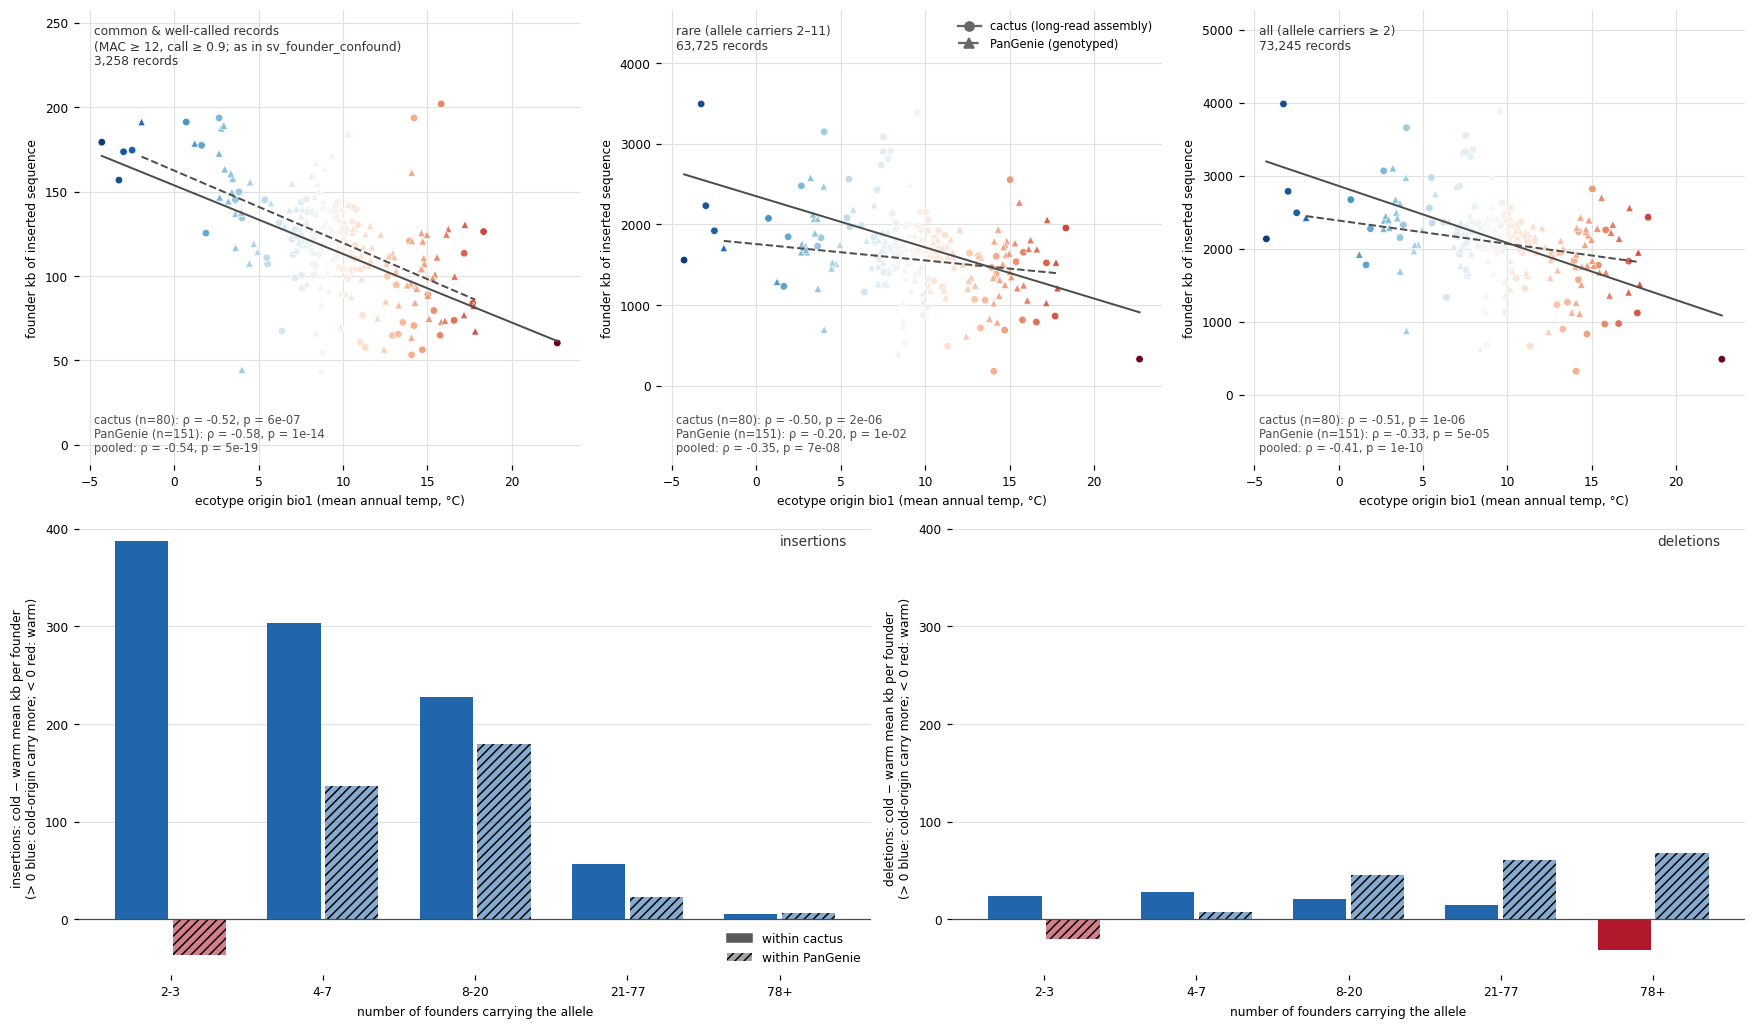

cactus founders per tertile: {'cold': 32, 'temperate': 23, 'warm': 25}  (of 77 each)

INSERTIONS, kb
set                     records   median cactus / PanGenie   rho pooled   rho cactus  rho PanGenie
common_wellcalled         3,258          118 / 121                -0.54        -0.52         -0.58
common                    9,510          387 / 520                -0.37        -0.54         -0.50
rare_rec2                63,725        1,804 / 1,599              -0.35        -0.50         -0.20
rare_rec2_wellcalled     20,076          410 / 393                -0.24        -0.39         -0.12
all_rec2                 73,245        2,232 / 2,138              -0.41        -0.51         -0.33
rare_min2                39,442        1,375 / 421                +0.02        +0.21         +0.15
all_min2                158,990        4,906 / 2,245              -0.17        -0.03         -0.24

cold - warm kb per founder, within panel half, by allele carrier count
                     2-3     4-7   

In [3]:

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
L=np.load(f"{G}/sv_origin_load_by_filter.npz",allow_pickle=True)
assert np.array_equal(L["founders"],F.founder.to_numpy())
lb1=L["bio1"]; lgrp=L["group"]; cac=F.is_cactus.to_numpy().astype(bool)
HALF=[("cactus",cac,"o","-"),("PanGenie",~cac,"^","--")]
LSTR=[tuple(x) for x in L["strata"]]
LSLAB=[f"{a}" if a==b else (f"{a}-{b}" if b<10**5 else f"{a}+") for a,b in LSTR]
SI=[i for i,(lo,hi) in enumerate(LSTR) if lo>=MINC]          # strata shown (singletons dropped)
SETS=[("common_wellcalled","common & well-called records\n(MAC ≥ 12, call ≥ 0.9; as in sv_founder_confound)"),
      ("rare_rec2","rare (allele carriers 2–11)"),
      ("all_rec2","all (allele carriers ≥ 2)")]
DIFF={}

def half_scatter(a,y,lab,nrec,ylab):
    style(a); txt=[]
    for h,m,mk,ls in HALF:
        a.scatter(lb1[m],y[m],c=lb1[m],cmap="RdBu_r",vmin=-5,vmax=23,s=24,marker=mk,edgecolors="white",linewidths=0.4)
        bb,c0=np.polyfit(lb1[m],y[m],1); xs=np.array([lb1[m].min(),lb1[m].max()]); a.plot(xs,c0+bb*xs,color="0.3",lw=1.3,ls=ls)
        r=stats.spearmanr(lb1[m],y[m]); txt.append(f"{h} (n={m.sum()}): ρ = {r.correlation:+.2f}, p = {r.pvalue:.0e}")
    r=stats.spearmanr(lb1,y); txt.append(f"pooled: ρ = {r.correlation:+.2f}, p = {r.pvalue:.0e}")
    a.annotate(f"{lab}\n{nrec:,} records",xy=(0.03,0.97),xycoords="axes fraction",va="top",fontsize=8,color="0.2")
    a.annotate("\n".join(txt),xy=(0.03,0.03),xycoords="axes fraction",fontsize=7.5,color="0.3")
    a.set_xlabel("ecotype origin bio1 (mean annual temp, °C)"); a.set_ylabel(ylab)
    rng_=y.max()-y.min(); a.set_ylim(y.min()-rng_*0.35,y.max()+rng_*0.35)

HALF_LEGEND=[Line2D([],[],marker="o",ls="-",color="0.4",label="cactus (long-read assembly)"),
             Line2D([],[],marker="^",ls="--",color="0.4",label="PanGenie (genotyped)")]

def diff_bars(axes,getK,unit,key):
    # cold - warm tertile means within each panel half, per carrier stratum; getK(t) -> [strata x founders]
    x=np.arange(len(SI)); w=0.38
    for a,(t,lab) in zip(axes,(("ins","insertions"),("del","deletions"))):
        style(a,axis="y"); K=getK(t)[SI]
        for j,(h,m,mk,ls) in enumerate(HALF):
            d=K[:,m&(lgrp=="cold")].mean(1)-K[:,m&(lgrp=="warm")].mean(1); DIFF[(key,t,h)]=d
            a.bar(x+(j-0.5)*w,d,w*0.92,color=[CG["cold"] if v>0 else CG["warm"] for v in d],linewidth=0,
                  hatch=None if h=="cactus" else "////",alpha=1 if h=="cactus" else 0.55)
        a.axhline(0,color="0.3",lw=0.8)
        a.set_xticks(x); a.set_xticklabels([LSLAB[i] for i in SI]); a.set_xlabel("number of founders carrying the allele")
        a.set_ylabel(f"{lab}: cold − warm mean {unit} per founder\n(> 0 blue: cold-origin carry more; < 0 red: warm)")
        a.annotate(lab,xy=(0.97,0.97),xycoords="axes fraction",ha="right",va="top",fontsize=9,color="0.2")
    ylo=min(a.get_ylim()[0] for a in axes); yhi=max(a.get_ylim()[1] for a in axes)
    for a in axes: a.set_ylim(ylo,yhi)
    axes[0].legend(handles=[Patch(color="0.35",label="within cactus"),Patch(facecolor="0.35",alpha=0.55,hatch="////",label="within PanGenie")],
                   frameon=False,fontsize=8,loc="lower right")

def print_diff(key,title):
    print(f"\n{title}")
    print(f"{'':<16}"+"".join(f"{LSLAB[i]:>8}" for i in SI))
    for (ks,t,h),d in DIFF.items():
        if ks==key: print(f"{t+' '+h:<16}"+"".join(f"{v:>+8.0f}" for v in d))

def draw_load(fname,measure="kb"):
    # measure = "kb" (inserted sequence) or "n" (number of SVs carried)
    unit="kb" if measure=="kb" else "number of SVs"
    fig,axd=plt.subplot_mosaic([["A","A","B","B","C","C"],["D","D","D","E","E","E"]],figsize=(16,9.4))
    ax=[axd[k] for k in "ABCDE"]
    for a,(f,lab) in zip(ax[:3],SETS):
        half_scatter(a,L[f"{measure}_ins_{f}"],lab,int(L[f"nrec_ins_{f}"]),
                     "founder kb of inserted sequence" if measure=="kb" else "founder number of insertions carried")
    ax[1].legend(handles=HALF_LEGEND,frameon=False,fontsize=7.5,loc="upper right")
    diff_bars(ax[3:],lambda t: L[f"{measure}_{t}_strata_rec"],unit,measure)
    fig.tight_layout(); fig.savefig(f"{G}/plots/{fname}",dpi=130,bbox_inches="tight"); plt.show()

def print_sets(t,measure):
    print(f"{'set':<22}{'records':>9}{'median cactus / PanGenie':>27}{'rho pooled':>13}{'rho cactus':>13}{'rho PanGenie':>14}")
    for f in ("common_wellcalled","common","rare_rec2","rare_rec2_wellcalled","all_rec2","rare_min2","all_min2"):
        y=L[f"{measure}_{t}_{f}"]; rr=[stats.spearmanr(lb1[m],y[m]).correlation for m in (np.ones_like(cac),cac,~cac)]
        print(f"{f:<22}{int(L[f'nrec_{t}_{f}']):>9,}{np.median(y[cac]):>13,.0f} / {np.median(y[~cac]):<11,.0f}{rr[0]:>+13.2f}{rr[1]:>+13.2f}{rr[2]:>+14.2f}")

draw_load("sv_origin_load_by_filter_min2.png")
print(f"cactus founders per tertile: {pd.crosstab(lgrp,cac)[True].to_dict()}  (of 77 each)\n")
print("INSERTIONS, kb"); print_sets("ins","kb")
print_diff("kb","cold - warm kb per founder, within panel half, by allele carrier count")
y=L["kb_ins_rare"]
print(f"\nsingleton layer (excluded): rare insertion records incl. singletons (MAC 1-11) -- median kb cactus / PanGenie = "
      f"{np.median(y[cac]):,.0f} / {np.median(y[~cac]):,.0f} ({np.median(y[cac])/np.median(y[~cac]):.1f}x); "
      f"rho vs bio1 pooled {stats.spearmanr(lb1,y).correlation:+.2f}")


The same figure counting **SVs instead of kb**: each founder's number of insertions carried
(top row), and the cold − warm difference in the number of SVs carried per founder, by locus
allele carrier count (bottom row).

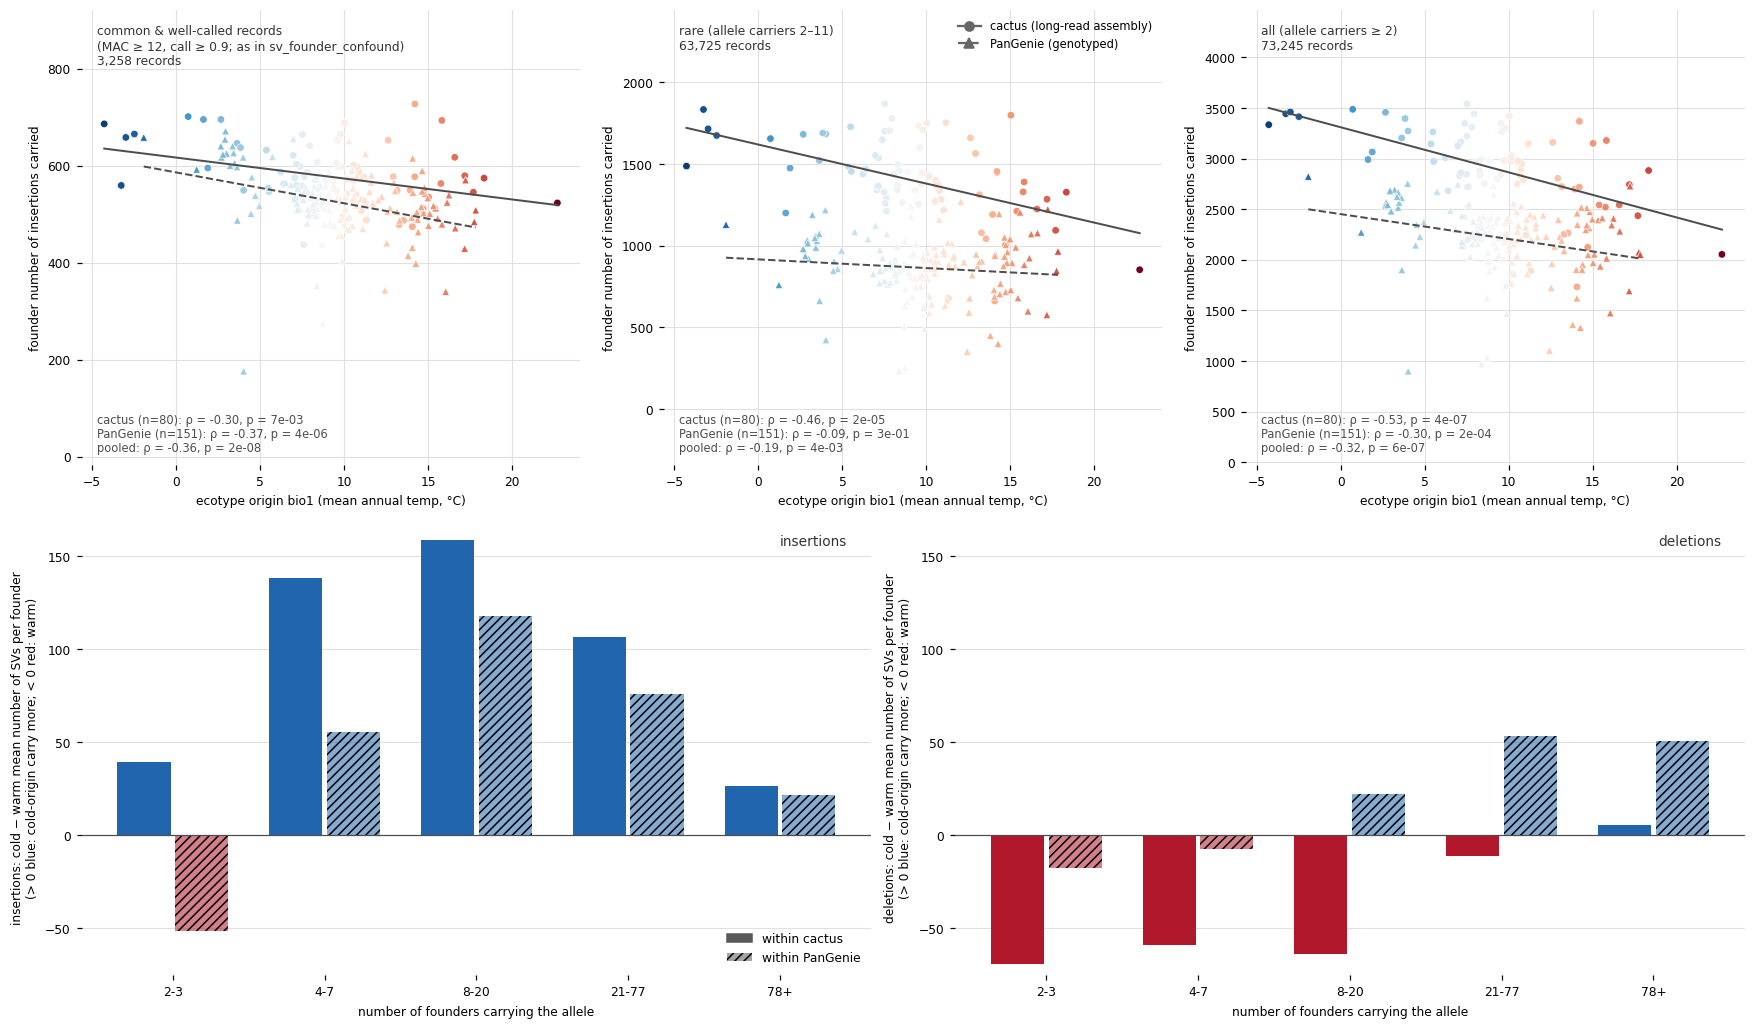

INSERTIONS, number carried
set                     records   median cactus / PanGenie   rho pooled   rho cactus  rho PanGenie
common_wellcalled         3,258          570 / 525                -0.36        -0.30         -0.37
common                    9,510        1,514 / 1,360              -0.50        -0.52         -0.47
rare_rec2                63,725        1,410 / 878                -0.19        -0.46         -0.09
rare_rec2_wellcalled     20,076          384 / 289                -0.09        -0.15         +0.00
all_rec2                 73,245        2,968 / 2,265              -0.32        -0.53         -0.30
rare_min2                39,442          514 / 195                +0.01        +0.22         +0.09
all_min2                158,990        3,778 / 2,289              -0.15        +0.12         -0.25

cold - warm number of SVs carried per founder, within panel half, by allele carrier count
                     2-3     4-7    8-20   21-77     78+
ins cactus           +40    +138 

In [4]:

draw_load("sv_origin_load_by_filter_min2_count.png",measure="n")
print("INSERTIONS, number carried"); print_sets("ins","n")
print_diff("n","cold - warm number of SVs carried per founder, within panel half, by allele carrier count")


The per-founder scatters for **deletions** (sequence present in TAIR10/Col-0 and absent from
the founder), same three sets and same panel-half split. Top row: number of deletions carried;
bottom row: kb deleted.

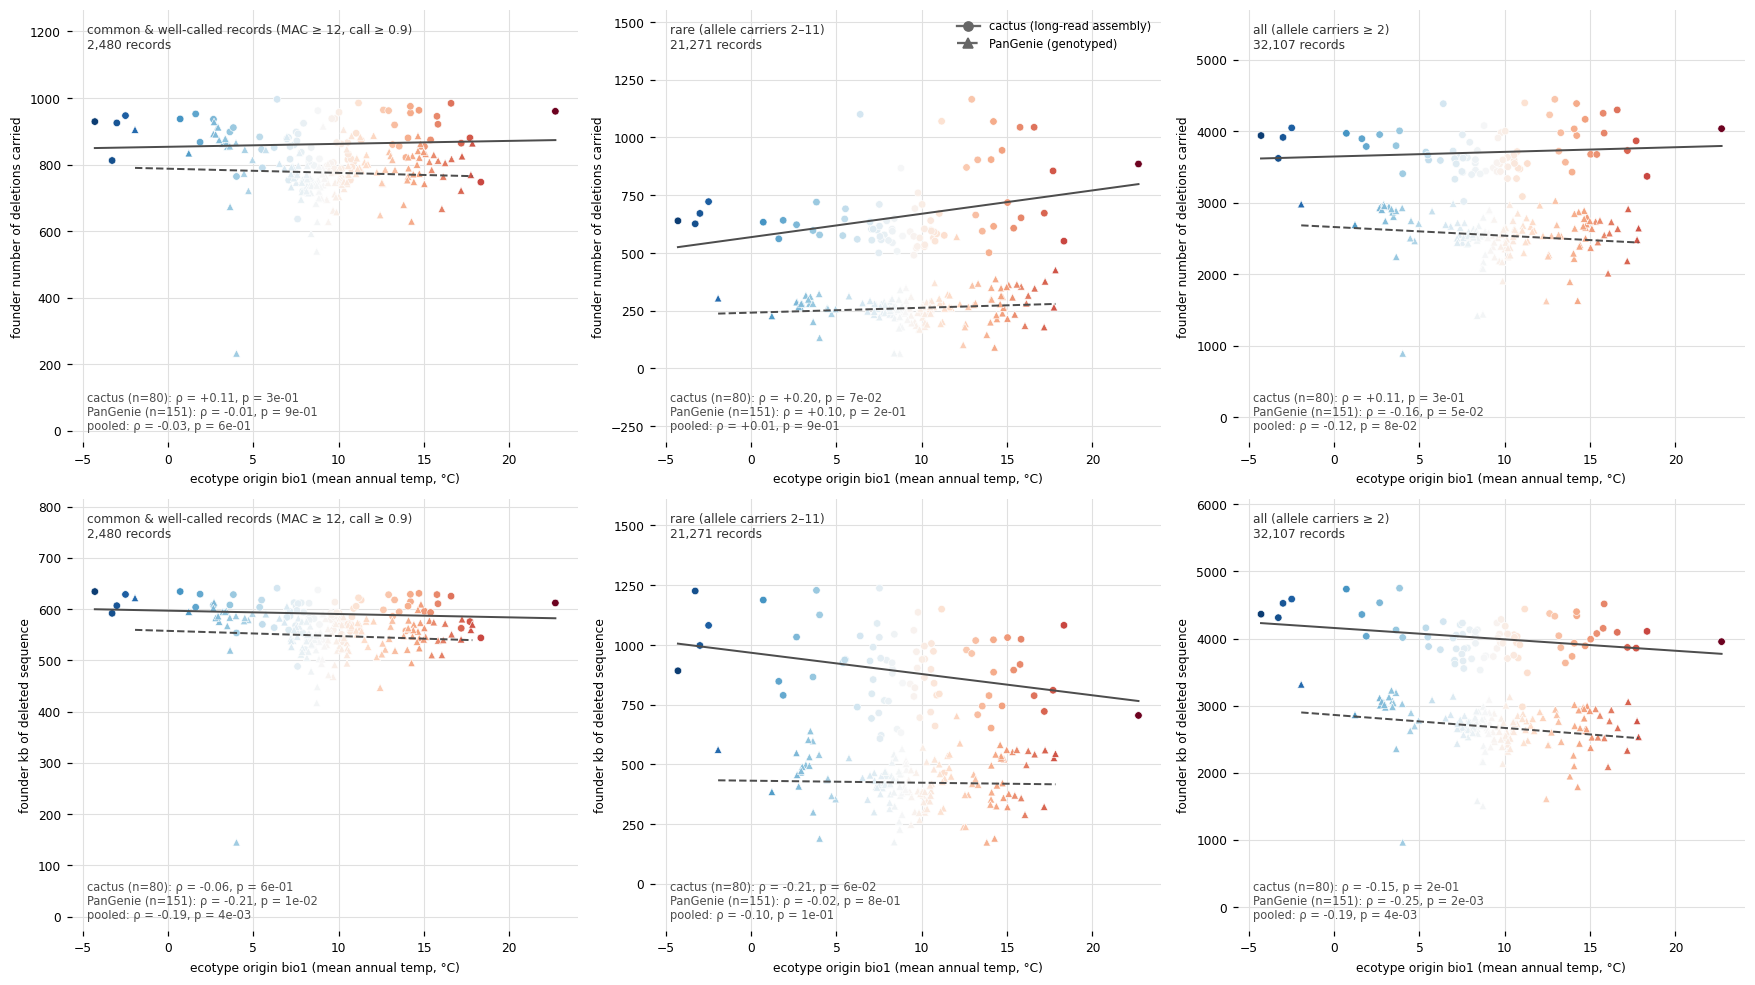

DELETIONS, number carried
set                     records   median cactus / PanGenie   rho pooled   rho cactus  rho PanGenie
common_wellcalled         2,480          863 / 772                -0.03        +0.11         -0.01
common                   10,746        2,944 / 2,207              -0.17        -0.04         -0.25
rare_rec2                21,271          604 / 265                +0.01        +0.20         +0.10
rare_rec2_wellcalled      3,144           70 / 46                 +0.08        +0.21         +0.12
all_rec2                 32,107        3,650 / 2,561              -0.12        +0.11         -0.16
rare_min2                19,329          526 / 204                +0.03        +0.28         +0.12
all_min2                 40,435        3,754 / 2,564              -0.11        +0.16         -0.16

DELETIONS, kb
set                     records   median cactus / PanGenie   rho pooled   rho cactus  rho PanGenie
common_wellcalled         2,480          593 / 551                -0

In [5]:

DSETS=[("common_wellcalled","common & well-called records (MAC ≥ 12, call ≥ 0.9)"),
       ("rare_rec2","rare (allele carriers 2–11)"),("all_rec2","all (allele carriers ≥ 2)")]
fig,ax=plt.subplots(2,3,figsize=(16,9))
for r,(ms,ylab) in enumerate((("n","founder number of deletions carried"),("kb","founder kb of deleted sequence"))):
    for c,(f,lab) in enumerate(DSETS):
        half_scatter(ax[r,c],L[f"{ms}_del_{f}"],lab,int(L[f"nrec_del_{f}"]),ylab)
ax[0,1].legend(handles=HALF_LEGEND,frameon=False,fontsize=7.5,loc="upper right")
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_origin_load_by_filter_min2_deletions.png",dpi=130,bbox_inches="tight"); plt.show()
print("DELETIONS, number carried"); print_sets("del","n")
print("\nDELETIONS, kb"); print_sets("del","kb")


### 2b. Controls: panel half, SNP divergence, SV call rate

Two things besides climate could set a founder's SV load. **Divergence**: a founder that differs
more from Col-0 at SNPs also carries more SVs of both types (`n_snp_all`, ALT alleles over all SNP
records). **Call quality**: a founder genotyped at more SV records can carry more of them
(`call_rate_sv`). Partial Spearman correlations of each load measure with origin bio1, adding
these controls in turn. Below: the cold − warm bars again (numbers of SVs), after regressing each
founder's count on SNP divergence within its panel half.

measure                                   none        + panel half    + SNP divergence      + SV call rate      cactus | SNP    PanGenie | SNP
ins kb common_wellcalled        -0.54 (5e-19)      -0.55 (2e-19)      -0.55 (7e-20)      -0.49 (3e-15)    -0.49 (5e-06)    -0.58 (5e-15)
ins kb all_rec2                 -0.41 (1e-10)      -0.40 (2e-10)      -0.42 (3e-11)      -0.33 (3e-07)    -0.47 (1e-05)    -0.34 (2e-05)
ins kb all_min2                 -0.17 (1e-02)      -0.18 (6e-03)      -0.25 (2e-04)      -0.10 (1e-01)    -0.27 (2e-02)    -0.24 (3e-03)
ins n common_wellcalled         -0.36 (2e-08)      -0.36 (3e-08)      -0.46 (2e-13)      -0.40 (4e-10)    -0.38 (6e-04)    -0.47 (2e-09)
ins n all_rec2                  -0.32 (6e-07)      -0.36 (1e-08)      -0.43 (7e-12)      -0.34 (1e-07)    -0.53 (6e-07)    -0.41 (2e-07)
ins n all_min2                  -0.15 (2e-02)      -0.15 (3e-02)      -0.30 (3e-06)      -0.15 (2e-02)    -0.23 (4e-02)    -0.34 (2e-05)
del kb common_wellcalled        -0.

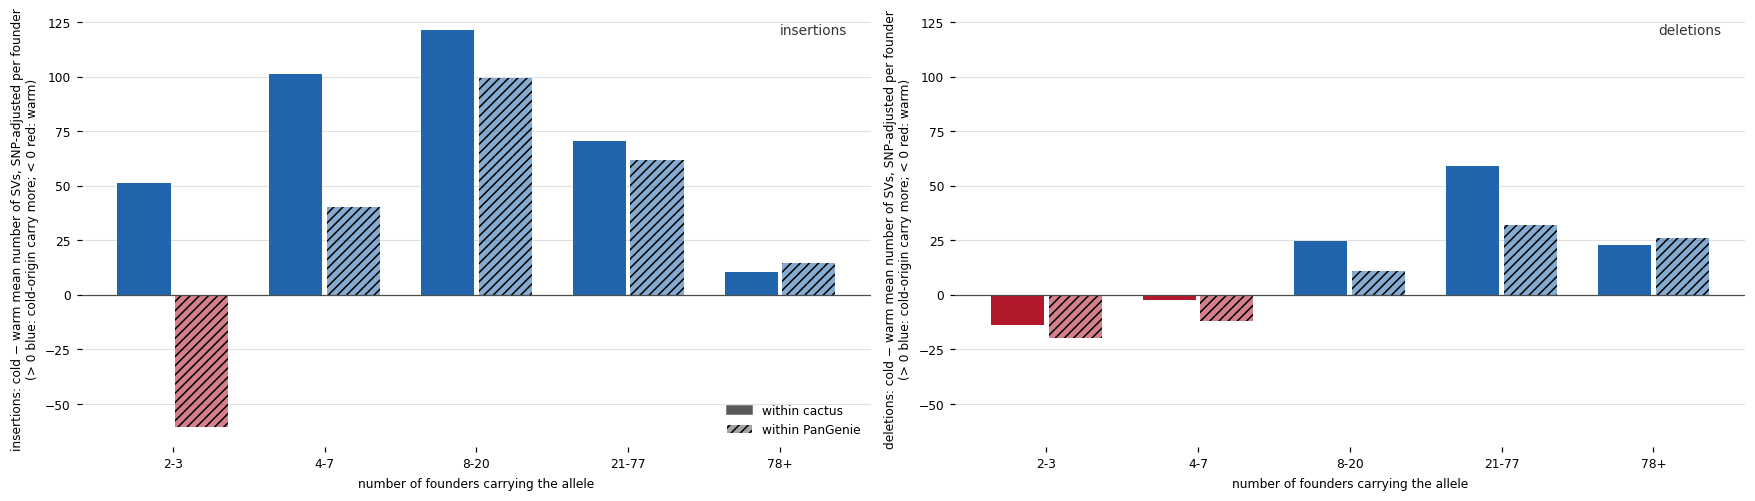


cold - warm number of SVs per founder after regressing on SNP divergence within half
                     2-3     4-7    8-20   21-77     78+
ins cactus           +51    +101    +121     +70     +10
ins PanGenie         -61     +40     +99     +62     +14
del cactus           -14      -3     +25     +59     +23
del PanGenie         -20     -12     +11     +32     +26


In [6]:

def partial_spearman(x,y,Zc):
    rx=stats.rankdata(x); ry=stats.rankdata(y)
    if Zc is None:
        r=stats.spearmanr(x,y).correlation; dof=len(x)-2
    else:
        A=np.column_stack([np.ones(len(x))]+[stats.rankdata(z) for z in Zc])
        ex=rx-A@np.linalg.lstsq(A,rx,rcond=None)[0]; ey=ry-A@np.linalg.lstsq(A,ry,rcond=None)[0]
        r=np.corrcoef(ex,ey)[0,1]; dof=len(x)-A.shape[1]-1
    t_=r*np.sqrt(dof/max(1e-12,1-r**2)); return r,2*stats.t.sf(abs(t_),dof)
snp=L["cov_n_snp_all"]; crs=L["cov_call_rate_sv"]; cf=cac.astype(float)
CTRL=[("none",None),("+ panel half",[cf]),("+ SNP divergence",[cf,snp]),("+ SV call rate",[cf,snp,crs])]
print(f"{'measure':<26}"+"".join(f"{c:>20}" for c,_ in CTRL)+f"{'cactus | SNP':>18}{'PanGenie | SNP':>18}")
for t in ("ins","del"):
    for ms in ("kb","n"):
        for f in ("common_wellcalled","all_rec2","all_min2"):
            y=L[f"{ms}_{t}_{f}"]; line=f"{t+' '+ms+' '+f:<26}"
            for _,Zc in CTRL:
                r,p=partial_spearman(lb1,y,Zc); line+=f"{r:>+11.2f} ({p:.0e})"
            for m in (cac,~cac):
                r,p=partial_spearman(lb1[m],y[m],[snp[m]]); line+=f"{r:>+9.2f} ({p:.0e})"
            print(line)
print(f"\nSNP divergence vs origin bio1: cactus rho {stats.spearmanr(lb1[cac],snp[cac]).correlation:+.2f}, "
      f"PanGenie rho {stats.spearmanr(lb1[~cac],snp[~cac]).correlation:+.2f}")

def resid_snp(t):
    K=L[f"n_{t}_strata_rec"].copy()
    for m in (cac,~cac):
        A=np.column_stack([np.ones(m.sum()),snp[m]])
        for i in range(K.shape[0]):
            K[i,m]=K[i,m]-A@np.linalg.lstsq(A,K[i,m],rcond=None)[0]
    return K
fig,ax=plt.subplots(1,2,figsize=(16,4.6))
diff_bars(list(ax),resid_snp,"number of SVs, SNP-adjusted","n_adj")
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_origin_load_count_snp_adjusted.png",dpi=130,bbox_inches="tight"); plt.show()
print_diff("n_adj","cold - warm number of SVs per founder after regressing on SNP divergence within half")


### 2c. Does the unit change the answer? Alleles vs events, common vs rare

The panel stores one record per distinct inserted **sequence**, so one event can appear as up to
~78 records (one per cactus assembly). Two ways to count what a founder carries:

- **allele** — count records, frequency = that record's carrier count;
- **event** — count Truvari events (`_build_event_map.py`, alleles of one bubble merged by
  sequence/size similarity), frequency = carriers of the event.

They can only disagree where an event has several alleles, which is the rare end: rare insertions
are 63,725 alleles but 21,273 events, while common insertions are 9,510 vs 11,354 — closer, though
not "nearly the same" the way alleles-vs-bubbles were (event is a stricter, more conservative merge
than the graph bubble, so it sits between allele and bubble on the rare end). Each figure is one row
per unit, one column per frequency class; points and ρ are split by panel half as before. First the
number of insertions carried, then the kb.

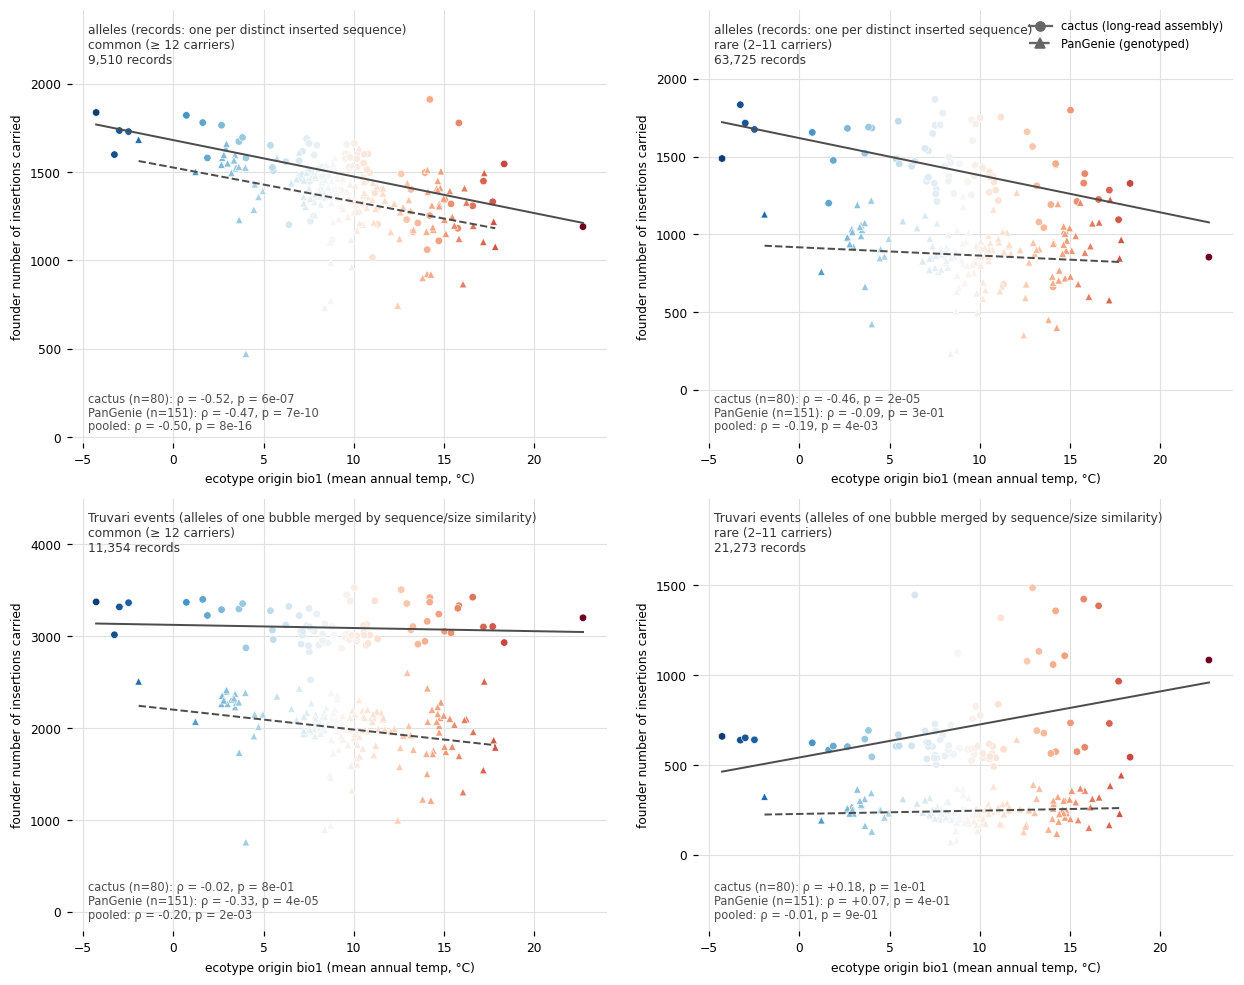

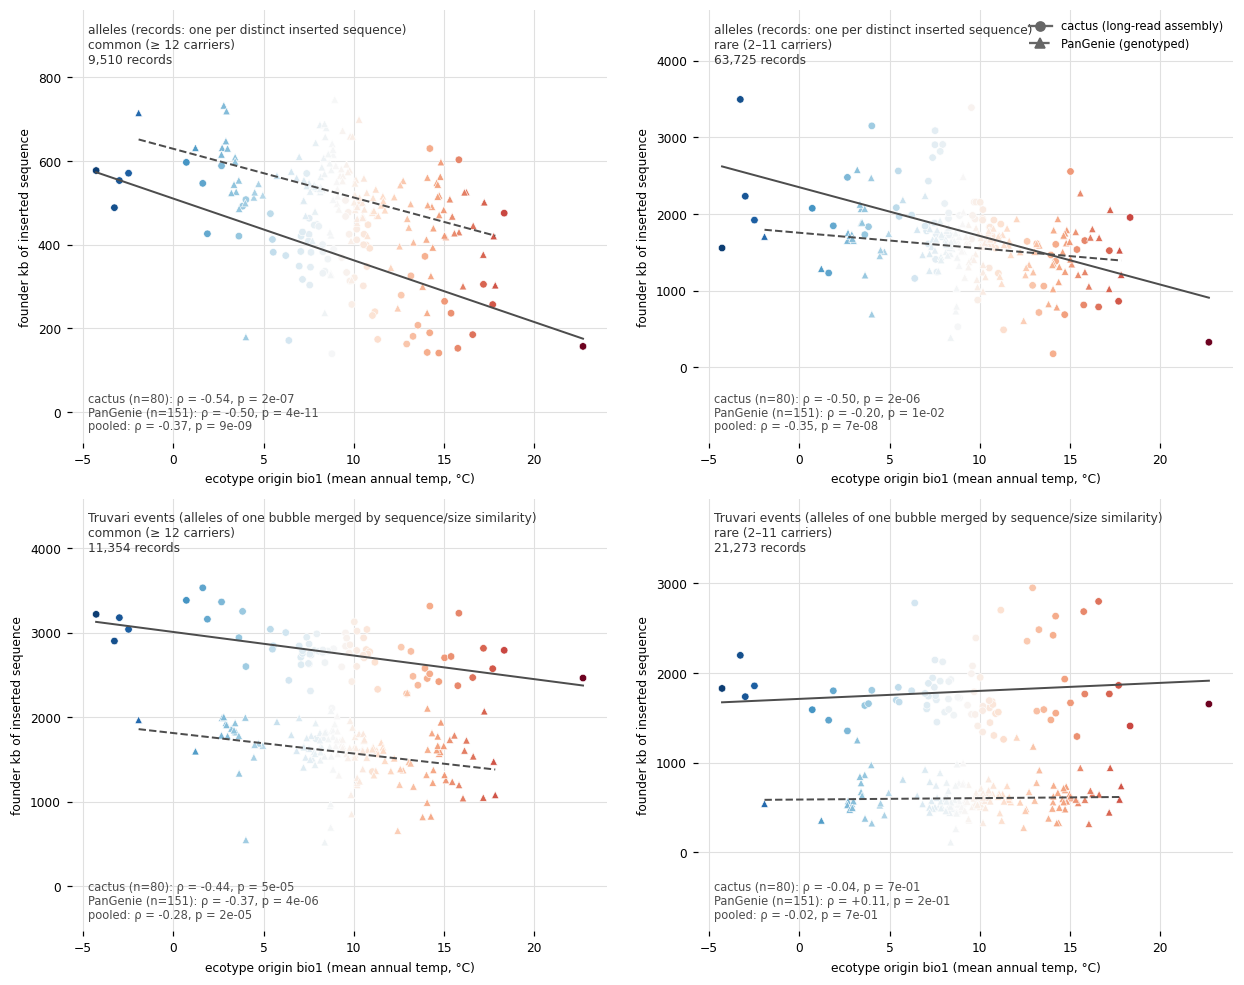

type unit    class       units  measure   rho pooled   rho cactus  rho PanGenie
ins  allele  common      9,510        n   -0.50 (8e-16)   -0.52 (6e-07)   -0.47 (7e-10)
ins  allele  common      9,510       kb   -0.37 (9e-09)   -0.54 (2e-07)   -0.50 (4e-11)
ins  allele  rare       63,725        n   -0.19 (4e-03)   -0.46 (2e-05)   -0.09 (3e-01)
ins  allele  rare       63,725       kb   -0.35 (7e-08)   -0.50 (2e-06)   -0.20 (1e-02)
ins  event   common     11,354        n   -0.20 (2e-03)   -0.02 (8e-01)   -0.33 (4e-05)
ins  event   common     11,354       kb   -0.28 (2e-05)   -0.44 (5e-05)   -0.37 (4e-06)
ins  event   rare       21,273        n   -0.01 (9e-01)   +0.18 (1e-01)   +0.07 (4e-01)
ins  event   rare       21,273       kb   -0.02 (7e-01)   -0.04 (7e-01)   +0.11 (2e-01)
del  allele  common     10,746        n   -0.17 (9e-03)   -0.04 (7e-01)   -0.25 (2e-03)
del  allele  common     10,746       kb   -0.22 (7e-04)   -0.06 (6e-01)   -0.35 (1e-05)
del  allele  rare       21,271        n 

In [7]:

U=np.load(f"{G}/sv_unit_compare_event.npz")
assert np.array_equal(U["founders"],F.founder.to_numpy()) and np.allclose(U["bio1"],lb1)
UNITS=[("allele","alleles (records: one per distinct inserted sequence)"),
       ("event","Truvari events (alleles of one bubble merged by sequence/size similarity)")]
CLS=[("common","common (≥ 12 carriers)"),("rare","rare (2–11 carriers)")]
def draw_unit(measure,fname,ylab):
    fig,ax=plt.subplots(2,2,figsize=(11.5,9))
    for r,(u,ulab) in enumerate(UNITS):
        for c,(cl,clab) in enumerate(CLS):
            half_scatter(ax[r,c],U[f"{measure}_ins_{u}_{cl}"],ulab+chr(10)+clab,int(U[f"nunit_ins_{u}_{cl}"]),ylab)
    ax[0,1].legend(handles=HALF_LEGEND,frameon=False,fontsize=7.5,loc="upper right")
    fig.tight_layout(); fig.savefig(f"{G}/plots/{fname}",dpi=130,bbox_inches="tight"); plt.show()
draw_unit("n","sv_unit_compare_count.png","founder number of insertions carried")
draw_unit("kb","sv_unit_compare_kb.png","founder kb of inserted sequence")

print(f"{'type':<5}{'unit':<8}{'class':<8}{'units':>9}{'measure':>9}{'rho pooled':>13}{'rho cactus':>13}{'rho PanGenie':>14}")
for t in ("ins","del"):
    for u,_ in UNITS:
        for cl,_ in CLS:
            for ms in ("n","kb"):
                y=U[f"{ms}_{t}_{u}_{cl}"]; rr=[stats.spearmanr(lb1[m],y[m]) for m in (np.ones_like(cac),cac,~cac)]
                print(f"{t:<5}{u:<8}{cl:<8}{int(U[f'nunit_{t}_{u}_{cl}']):>9,}{ms:>9}"
                      +"".join(f"{x.correlation:>+8.2f} ({x.pvalue:.0e})" for x in rr))


### 2d. Frequency spectra — alleles vs events

Same view as `sv_insertion_landing_vs_purging.ipynb`: the cumulative distribution of ALT frequency
among called founders, one line per class. Insertions and deletions each appear twice — counted as
**alleles** (records: one per distinct inserted sequence) and as **events** (Truvari events: an
event's alleles merged by sequence/size similarity, carriers = union) — with **SNPs and short
indels as the reference**, since demography moves every class alike and only class *differences*
speak to selection.

**Panel 1** — the spectra, all classes pooled over founders. **Panel 2** — share of variants below
1% / 5% / 10% frequency, annotated with the fold difference from SNPs.

**Panels 3 and 4 split the founders by origin climate, and count insertions BOTH ways.** Each line
is computed *within one origin tertile*: the sample is that tertile's founders, so frequency is
among ecotypes from that climate. Panel 3 is the raw spectrum — warm-origin ecotypes look more
rare-skewed, but their SNPs are too, so panel 4 subtracts **that group's own SNP spectrum**. A group
purging insertions harder shows a bigger gap in panel 4, not merely a steeper line in panel 3.

**The allele-vs-event gap in panel 4 is most of the point.** Counting alleles inflates every group's
excess over its own SNPs; counting the same events, the gap shrinks substantially (from a ~30-point
excess to ~10–13 points, §2d table) — most of that shrinkage is one insertion split into one allele
per assembly carrying it, not selection, though unlike the old graph-bubble unit the excess does not
fully disappear. In this run, warm-origin founders segregate more insertion events than cold at the
whole-panel level (14,095 vs 11,028, well-called, singletons kept) — the cold tertile being
assembly-richer (32 cactus founders vs 25) does not reverse that ordering here the way it did for the
older bubble comparison; see the printed table for the exact per-tertile totals.

Line style means the same thing in every panel: **dashed = alleles, solid = events**; colour is
class (panel 1) or origin tertile (panels 3–4).

**The whole panel, analysed together** (231 founders). Both sequencing routes are represented in
every origin tertile — cactus assemblies 32 / 23 / 25 and PanGenie-genotyped 45 / 54 / 52 across
cold / temperate / warm — so the climate contrast does not need the panel split in two. The cold
tertile is the assembly-richer one, which is the standing caveat repeated at the end. A variant enters if it has
≥ 1 carrier and is **well called** — genotyped in ≥ 90% of the founder set, the same filter the
other notebooks use. The printed table repeats every number without that filter.

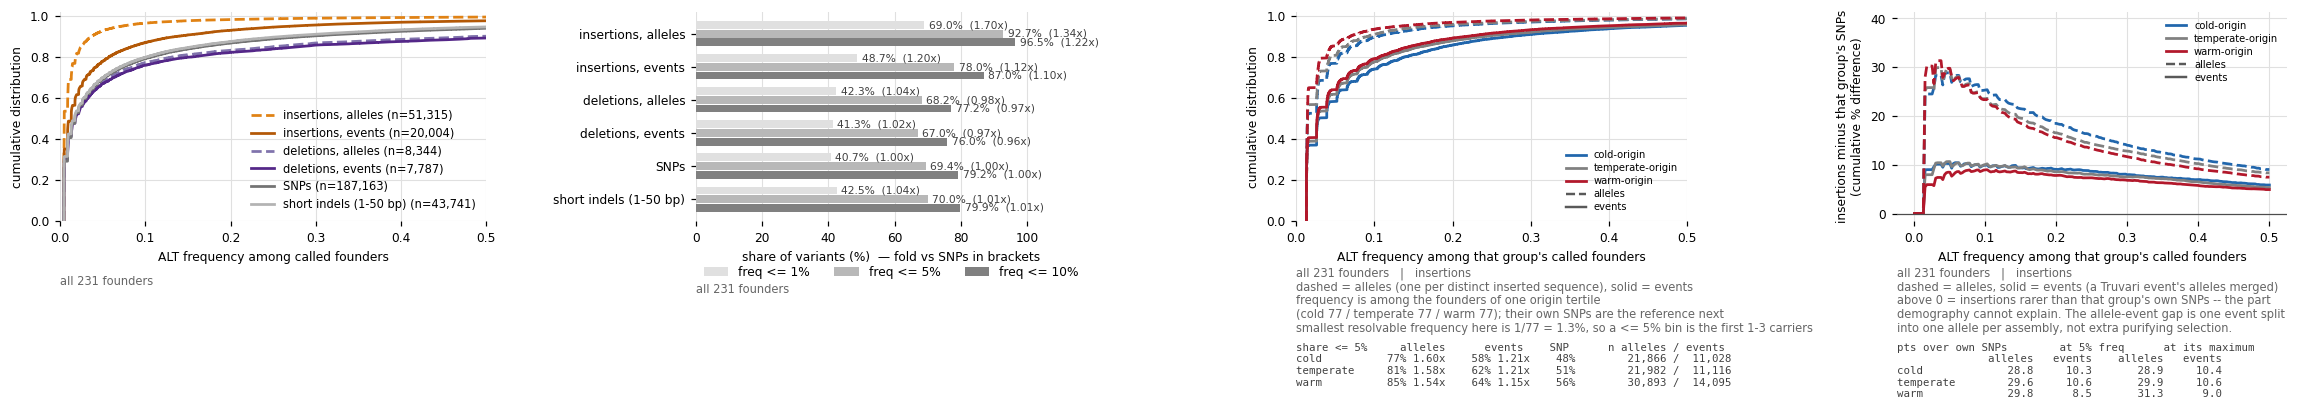

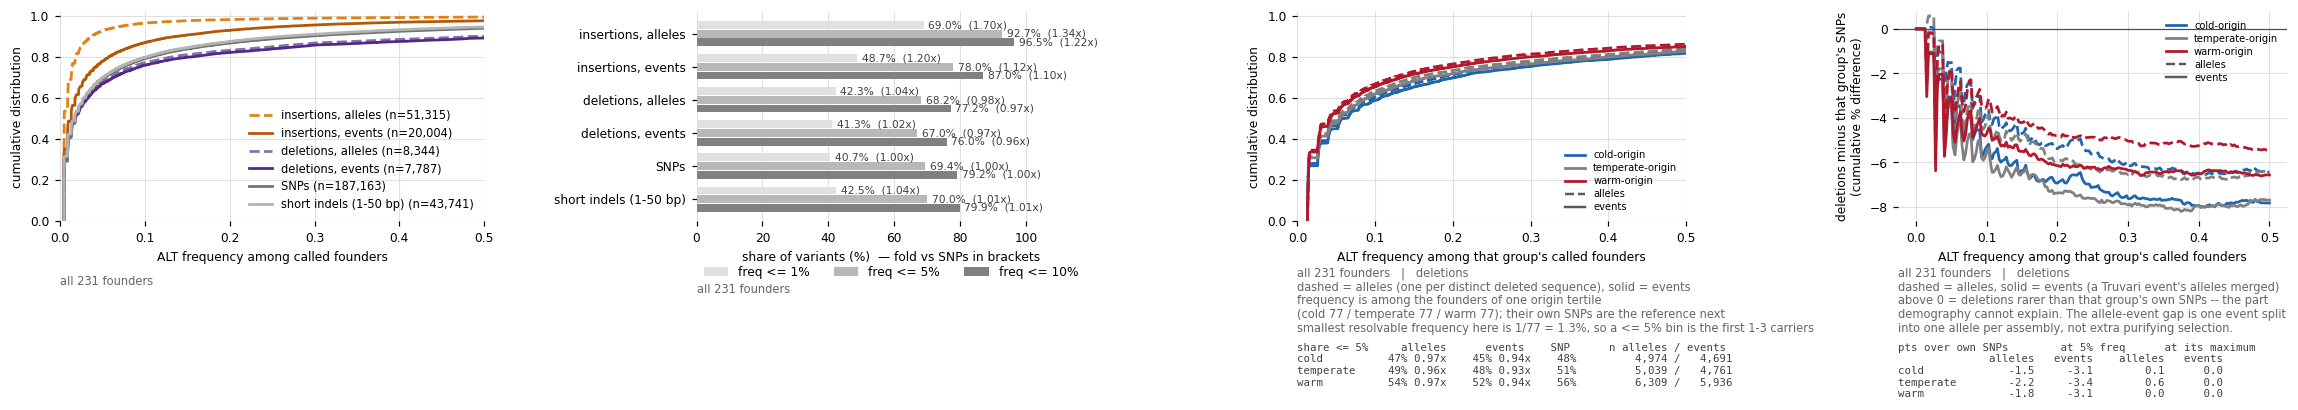


all founders -- raw frequency among called founders (no projection)
class                   variants     <=1%     <=5%    <=10%   median   <=5% fold vs SNP
insertions, alleles       51,315    69.0%    92.7%    96.5%    0.005              1.34x
insertions, events        20,004    48.7%    78.0%    87.0%    0.013              1.12x
deletions, alleles         8,344    42.3%    68.2%    77.2%    0.018              0.98x
deletions, events          7,787    41.3%    67.0%    76.0%    0.018              0.97x
SNPs                     187,163    40.7%    69.4%    79.2%    0.017              1.00x
short indels (1-50 bp)    43,741    42.5%    70.0%    79.9%    0.017              1.01x
  by origin tertile, insertion events vs that group's SNPs (share <= 5%): cold 58.3% vs SNP 48.0% (ratio 1.21), temperate 61.8% vs SNP 51.1% (ratio 1.21), warm 64.0% vs SNP 55.6% (ratio 1.15)
  cross-check, projected to 60 called founders (no call-rate filter): insertion events 40.5% singleton vs SNPs 34.1%
  with

In [8]:

S=np.load(f"{G}/sv_sfs_event.npz")
NP=int(S["nproj"]); NPG=int(S["nproj_group"])
FQ="freqw"      # well-called only (>= 90% of the founder set called); "freq" = no call-rate filter
SFCL=[("ins_allele","insertions, alleles","#E08214","--"),("ins_event","insertions, events","#B35806","-"),
      ("del_allele","deletions, alleles","#8073AC","--"),("del_event","deletions, events","#542788","-"),
      ("snp","SNPs","0.45","-"),("indel","short indels (1-50 bp)","0.7","-")]
THR=[0.01,0.05,0.10]
def ecdf(a,ax,color,ls,lab):
    v=np.sort(a); ax.plot(v,np.arange(1,v.size+1)/v.size,color=color,ls=ls,lw=1.8,label=lab)
SETLAB={"all":"all 231 founders","pangenie":"151 PanGenie-genotyped founders only",
        "cactus":"80 long-read (cactus) assembly founders only"}
FSET={"all":lambda F:F,"pangenie":lambda F:F[~F.is_cactus.astype(bool)],"cactus":lambda F:F[F.is_cactus.astype(bool)]}
def draw_sfs(setname,fname,gcls="ins",glab="insertion"):
    fig,ax=plt.subplots(1,4,figsize=(21,4.8),gridspec_kw=dict(width_ratios=[1.2,1.1,1.1,1.1]))
    SL=SETLAB[setname]; fset=FSET[setname](F)
    NF={g:int((fset.group==g).sum()) for g in ("cold","temperate","warm")}
    style(ax[0])
    for c,lab,col,ls in SFCL:
        f=S[f"{FQ}_{setname}_all_{c}"]
        ecdf(f,ax[0],col,ls,f"{lab} (n={f.size:,})")
    ax[0].set_xlim(0,0.5); ax[0].set_ylim(0,1.02)
    ax[0].set_xlabel("ALT frequency among called founders"); ax[0].set_ylabel("cumulative distribution")
    ax[0].legend(frameon=False,fontsize=7.5,loc="lower right")
    style(ax[1],axis="x")
    thr=[t for t in THR if t>1.0/len(fset)]          # 1% is below 1/80 in the cactus set -> undefined
    ref={t:(S[f"{FQ}_{setname}_all_snp"]<=t).mean() for t in thr}
    yy=np.arange(len(SFCL))[::-1]; h=0.26
    offs=np.linspace(h,-h,len(thr)) if len(thr)>1 else [0.0]
    for off,t,shade in zip(offs,thr,["0.88","0.72","0.5"][-len(thr):]):
        vals=[100*(S[f"{FQ}_{setname}_all_{c}"]<=t).mean() for c,_,_,_ in SFCL]
        ax[1].barh(yy+off,vals,height=h*0.92,color=shade,linewidth=0,label=f"freq <= {int(t*100)}%")
        for y,v in zip(yy,vals):
            ax[1].annotate(f"{v:.1f}%  ({v/(100*ref[t]):.2f}x)",(v,y+off),xytext=(3,0),textcoords="offset points",
                           va="center",fontsize=7,color="0.25")
    ax[1].set_yticks(yy); ax[1].set_yticklabels([c[1] for c in SFCL],fontsize=8); ax[1].set_xlim(0,118)
    ax[1].set_xlabel("share of variants (%)  — fold vs SNPs in brackets")
    ax[1].legend(frameon=False,fontsize=8,loc="upper center",bbox_to_anchor=(0.5,-0.16),ncol=len(thr))
    ax[1].annotate(SL+("" if len(thr)==len(THR) else
                   f"\n(freq <= 1% omitted: below 1/{len(fset)} = {100/len(fset):.2f}%, not resolvable)"),
                   xy=(0.0,-0.30),xycoords="axes fraction",ha="left",va="top",fontsize=7.5,color="0.4")
    style(ax[2])
    UNIT=((f"{gcls}_allele","--"),(f"{gcls}_event","-"))   # dashed = alleles, solid = events, as in panel 1
    GH=[]; srows=[f"{'share <= 5%':<11}{'alleles':>12}{'events':>12}{'SNP':>7}{'n alleles / events':>24}"]
    for g in ("cold","temperate","warm"):
        fa=S[f"{FQ}_{setname}_{g}_{gcls}_allele"]; fb=S[f"{FQ}_{setname}_{g}_{gcls}_event"]; fs=S[f"{FQ}_{setname}_{g}_snp"]
        for u,ls in UNIT: ecdf(S[f"{FQ}_{setname}_{g}_{u}"],ax[2],CG[g],ls,None)
        A=(fa<=0.05).mean(); B=(fb<=0.05).mean(); N=(fs<=0.05).mean()
        srows.append(f"{g:<11}{100*A:>5.0f}% {A/N:>4.2f}x{100*B:>6.0f}% {B/N:>4.2f}x{100*N:>6.0f}%"
                     f"{fa.size:>14,} /{fb.size:>8,}")
        GH.append(plt.Line2D([0],[0],color=CG[g],lw=1.8,label=f"{g}-origin"))
    UH=[plt.Line2D([0],[0],color="0.35",lw=1.6,ls="--",label="alleles"),
        plt.Line2D([0],[0],color="0.35",lw=1.6,ls="-",label="events")]
    ax[2].set_xlim(0,0.5); ax[2].set_ylim(0,1.02)
    ax[2].set_xlabel("ALT frequency among that group's called founders"); ax[2].set_ylabel("cumulative distribution")
    ax[2].legend(handles=GH+UH,frameon=False,fontsize=6.5,loc="lower right",labelspacing=0.3)
    ax[0].annotate(SL,xy=(0.0,-0.26),xycoords="axes fraction",ha="left",va="top",fontsize=7.5,color="0.4")
    ax[2].annotate(f"{SL}   |   {glab}s\n"
                   f"dashed = alleles (one per distinct {'inserted' if gcls=='ins' else 'deleted'} sequence), solid = events\n"
                   f"frequency is among the founders of one origin tertile\n"
                   f"(cold {NF['cold']} / temperate {NF['temperate']} / warm {NF['warm']}); their own SNPs are the reference next\n"
                   f"smallest resolvable frequency here is 1/{min(NF.values())} = {100/min(NF.values()):.1f}%, "
                   f"so a <= 5% bin is {'singletons only' if 100/min(NF.values())>2.5 else 'the first 1-3 carriers'}",
                   xy=(0.0,-0.22),xycoords="axes fraction",ha="left",va="top",fontsize=7.5,color="0.4")
    ax[2].annotate("\n".join(srows),xy=(0.0,-0.58),xycoords="axes fraction",ha="left",va="top",
                   family="monospace",fontsize=7,color="0.25")
    style(ax[3]); gx=np.linspace(0,0.5,201); dtop=0.0
    drows=[f"{'pts over own SNPs':<12}{'at 5% freq':>18}{'at its maximum':>20}",
           f"{'':<12}{'alleles':>9}{'events':>9}{'alleles':>11}{'events':>9}"]
    for g in ("cold","temperate","warm"):
        fs=S[f"{FQ}_{setname}_{g}_snp"]; sn=np.searchsorted(np.sort(fs),gx)/fs.size; at5={}; mx={}
        for u,ls in UNIT:
            f=S[f"{FQ}_{setname}_{g}_{u}"]
            d=100*(np.searchsorted(np.sort(f),gx)/f.size-sn)
            ax[3].plot(gx,d,color=CG[g],lw=1.8,ls=ls)
            dtop=max(dtop,d.max()); at5[u]=d[np.searchsorted(gx,0.05)]; mx[u]=d.max()
        drows.append(f"{g:<12}{at5[f'{gcls}_allele']:>9.1f}{at5[f'{gcls}_event']:>9.1f}"
                     f"{mx[f'{gcls}_allele']:>11.1f}{mx[f'{gcls}_event']:>9.1f}")
    ax[3].axhline(0,color="0.3",lw=0.8)
    ax[3].set_ylim(top=dtop*1.32)                                     # headroom so the legend clears the curves
    ax[3].set_xlabel("ALT frequency among that group's called founders")
    ax[3].set_ylabel(f"{glab}s minus that group's SNPs\n(cumulative % difference)")
    ax[3].legend(handles=GH+UH,frameon=False,fontsize=6.5,loc="upper right",labelspacing=0.3)
    ax[3].annotate(f"{SL}   |   {glab}s\n"
                   "dashed = alleles, solid = events (a Truvari event's alleles merged)\n"
                   f"above 0 = {glab}s rarer than that group's own SNPs -- the part\n"
                   "demography cannot explain. The allele-event gap is one event split\n"
                   "into one allele per assembly, not extra purifying selection.",
                   xy=(0.0,-0.22),xycoords="axes fraction",ha="left",va="top",fontsize=7.5,color="0.4")
    ax[3].annotate("\n".join(drows),xy=(0.0,-0.58),xycoords="axes fraction",ha="left",va="top",
                   family="monospace",fontsize=7,color="0.25")
    fig.tight_layout(); fig.savefig(f"{G}/plots/{fname}",dpi=130,bbox_inches="tight"); plt.show()
draw_sfs("all","sv_sfs_all_founders.png")
draw_sfs("all","sv_sfs_all_founders_del.png","del","deletion")

for setname in ("all",):
    print(f"\n{setname} founders -- raw frequency among called founders (no projection)")
    print(f"{'class':<22}{'variants':>10}{'<=1%':>9}{'<=5%':>9}{'<=10%':>9}{'median':>9}{'<=5% fold vs SNP':>19}")
    ref=(S[f"{FQ}_{setname}_all_snp"]<=0.05).mean()
    for c,lab,_,_ in SFCL:
        f=S[f"{FQ}_{setname}_all_{c}"]
        print(f"{lab:<22}{f.size:>10,}{100*(f<=0.01).mean():>8.1f}%{100*(f<=0.05).mean():>8.1f}%"
              f"{100*(f<=0.10).mean():>8.1f}%{np.median(f):>9.3f}{(f<=0.05).mean()/ref:>18.2f}x")
    print("  by origin tertile, insertion events vs that group's SNPs (share <= 5%): "+", ".join(
        f"{g} {100*(S[f'{FQ}_{setname}_{g}_ins_event']<=0.05).mean():.1f}% vs SNP "
        f"{100*(S[f'{FQ}_{setname}_{g}_snp']<=0.05).mean():.1f}% "
        f"(ratio {(S[f'{FQ}_{setname}_{g}_ins_event']<=0.05).mean()/(S[f'{FQ}_{setname}_{g}_snp']<=0.05).mean():.2f})"
        for g in ("cold","temperate","warm")))
    v=S[f"{setname}_all_ins_event"]; vs=S[f"{setname}_all_snp"]; kp=v.size-1
    print(f"  cross-check, projected to {kp} called founders (no call-rate filter): insertion events "
          f"{100*(v[1]/v[1:kp].sum()):.1f}% singleton vs SNPs {100*(vs[1]/vs[1:kp].sum()):.1f}%")
    print(f"  without the call-rate filter, share <= 5%: "+", ".join(
        f"{lab} {100*(S[f'freq_{setname}_all_{c}']<=0.05).mean():.1f}% (n={S[f'freq_{setname}_all_{c}'].size:,})" for c,lab,_,_ in SFCL))


### 2e. Saturation — how many, not what share

The spectra in 2d are normalised to 1, so they carry **shape only**: a group with half as many
insertions gives the same curve. This panel plots the **cumulative count** instead — the number of
variants in that group at frequency ≤ x — so each curve rises and then plateaus at the group's total.

Read it two ways: the **height of the plateau** is the total number of alleles (dashed) or events
(solid) segregating in that tertile, and **where the curve rises** is the frequency at which that
total accumulates. A group whose curve climbs early and flattens low has many rare variants and few
in total; one that keeps climbing to the right carries its variants at higher frequency.

The x-axis runs to 1.0 here rather than 0.5, so the curves reach their true totals.

**Filters.** Well-called is decided **once over all 231 founders** (≥ 90% called), not per tertile —
filtering per tertile made the three curves different variant sets, and since call rate correlates
with origin climate among the PanGenie founders that difference was itself climate-structured. A
tertile then contributes only "does this segregate here" (≥ 1 carrier). Frequencies are still within
the tertile.

**Three versions**, by panel-wide carrier floor: all units, **≥ 2** (private removed), and **≥ 12**
(common only, the MAF ~5% floor the rest of the project uses). The second removes **private units** — panel-wide
carrier count ≥ 2 required for both the allele and its event — because a variant carried by a single
ecotype cannot be distinguished from an assembly artefact, and these curves are *counts*, where that
uncertainty accumulates rather than showing up as a visible rare tail.

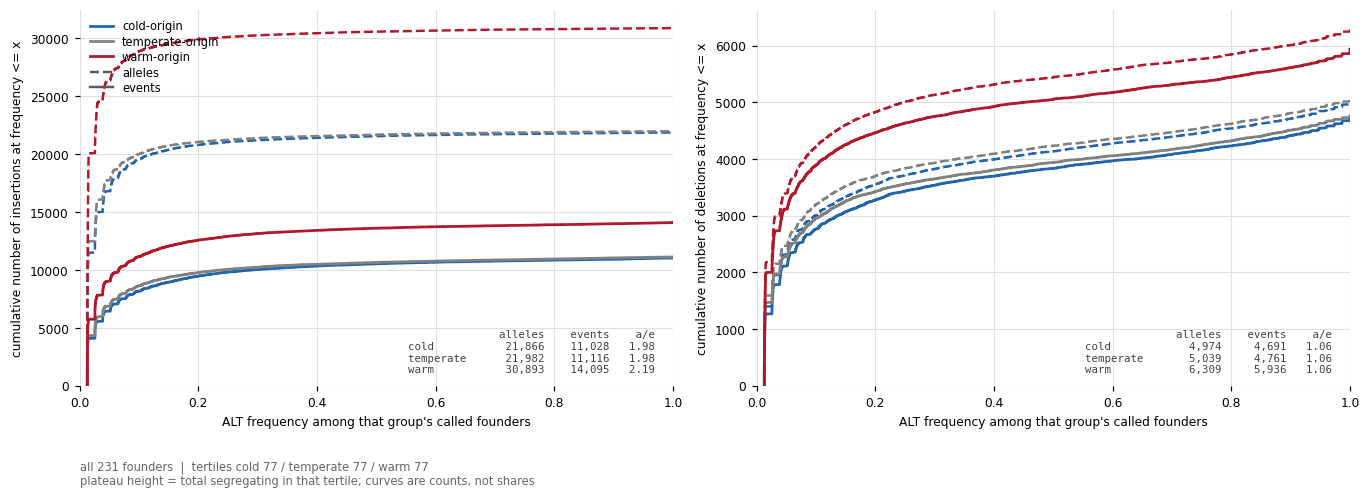

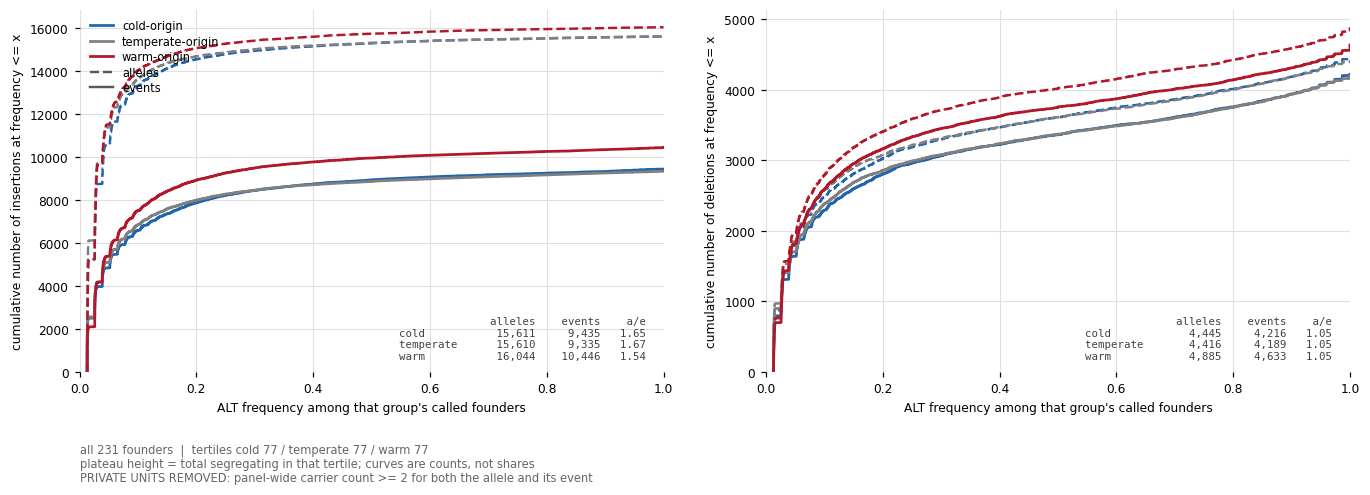

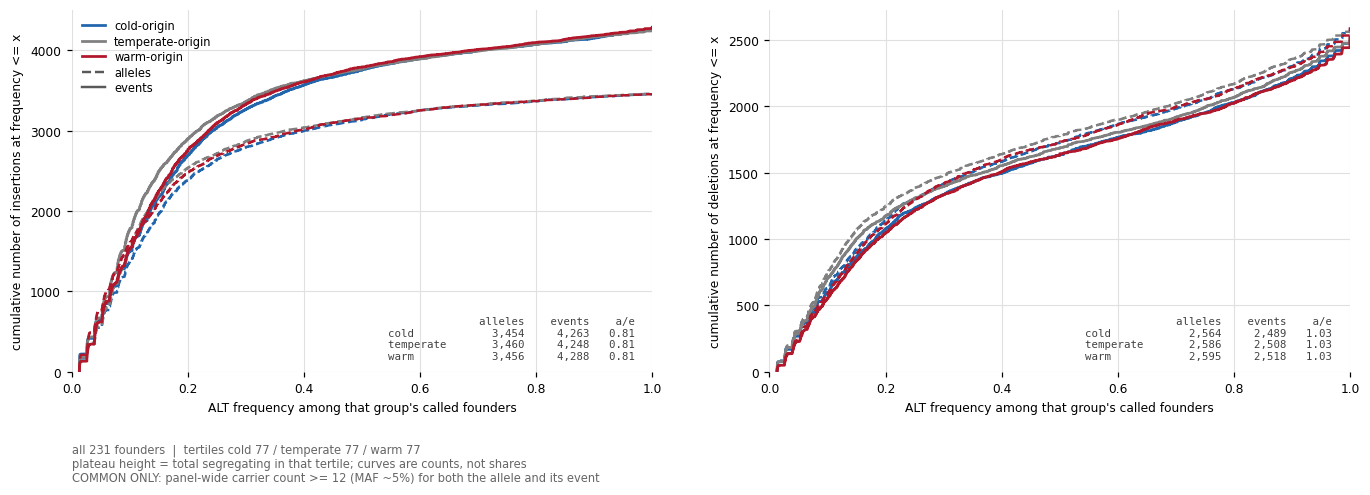


insertions, singletons kept: totals segregating in each tertile
group         alleles    events   alleles/event  median freq (a)  median freq (e)
cold           21,866    11,028            1.98           0.0143           0.0286
temperate      21,982    11,116            1.98           0.0143           0.0270
warm           30,893    14,095            2.19           0.0143           0.0267

deletions, singletons kept: totals segregating in each tertile
group         alleles    events   alleles/event  median freq (a)  median freq (e)
cold            4,974     4,691            1.06           0.0541           0.0580
temperate       5,039     4,761            1.06           0.0526           0.0541
warm            6,309     5,936            1.06           0.0411           0.0423

insertions, private units removed (panel MAC >= 2): totals segregating in each tertile
group         alleles    events   alleles/event  median freq (a)  median freq (e)
cold           15,611     9,435            1.

In [9]:


def draw_sat(setname,fname,fq=FQ,note=""):
    fig,ax=plt.subplots(1,2,figsize=(12.5,4.6))
    SL=SETLAB[setname]; fset=FSET[setname](F)
    NF={g:int((fset.group==g).sum()) for g in ("cold","temperate","warm")}
    for a,(gcls,glab) in zip(ax,(("ins","insertion"),("del","deletion"))):
        style(a)
        rows=[f"{'':<11}{'alleles':>10}{'events':>10}{'a/e':>7}"]
        for g in ("cold","temperate","warm"):
            fa=np.sort(S[f"{fq}_{setname}_{g}_{gcls}_allele"]); fb=np.sort(S[f"{fq}_{setname}_{g}_{gcls}_event"])
            a.plot(fa,np.arange(1,fa.size+1),color=CG[g],ls="--",lw=1.6)
            a.plot(fb,np.arange(1,fb.size+1),color=CG[g],ls="-",lw=1.8)
            rows.append(f"{g:<11}{fa.size:>10,}{fb.size:>10,}{fa.size/fb.size:>7.2f}")
        a.set_xlim(0,1.0); a.set_ylim(bottom=0)
        a.set_xlabel("ALT frequency among that group's called founders")
        a.set_ylabel(f"cumulative number of {glab}s at frequency <= x")
        a.annotate("\n".join(rows),xy=(0.97,0.03),xycoords="axes fraction",ha="right",va="bottom",
                   family="monospace",fontsize=7,color="0.25")
    ax[0].legend(handles=[plt.Line2D([0],[0],color=CG[g],lw=1.8,label=f"{g}-origin") for g in ("cold","temperate","warm")]
                 +[plt.Line2D([0],[0],color="0.35",lw=1.6,ls="--",label="alleles"),
                   plt.Line2D([0],[0],color="0.35",lw=1.6,ls="-",label="events")],
                 frameon=False,fontsize=7.5,loc="upper left",labelspacing=0.3)
    ax[0].annotate(f"{SL}  |  tertiles cold {NF['cold']} / temperate {NF['temperate']} / warm {NF['warm']}\n"
                   "plateau height = total segregating in that tertile; curves are counts, not shares"
                   +(f"\n{note}" if note else ""),
                   xy=(0.0,-0.20),xycoords="axes fraction",ha="left",va="top",fontsize=7.5,color="0.4")
    fig.tight_layout(); fig.savefig(f"{G}/plots/{fname}",dpi=130,bbox_inches="tight"); plt.show()

draw_sat("all","sv_sfs_saturation.png")
draw_sat("all","sv_sfs_saturation_nopriv.png","freqw2",
         "PRIVATE UNITS REMOVED: panel-wide carrier count >= 2 for both the allele and its event")
draw_sat("all","sv_sfs_saturation_common.png","freqw12",
         "COMMON ONLY: panel-wide carrier count >= 12 (MAF ~5%) for both the allele and its event")

for fq,ftag in ((FQ,"singletons kept"),("freqw2","private units removed (panel MAC >= 2)"),
                ("freqw12","common only (panel MAC >= 12)")):
  for gcls,glab in (("ins","insertions"),("del","deletions")):
    print(f"\n{glab}, {ftag}: totals segregating in each tertile")
    print(f"{'group':<11}{'alleles':>10}{'events':>10}{'alleles/event':>16}{'median freq (a)':>17}{'median freq (e)':>17}")
    for g in ("cold","temperate","warm"):
        fa=S[f"{fq}_all_{g}_{gcls}_allele"]; fb=S[f"{fq}_all_{g}_{gcls}_event"]
        print(f"{g:<11}{fa.size:>10,}{fb.size:>10,}{fa.size/fb.size:>16.2f}{np.median(fa):>17.4f}{np.median(fb):>17.4f}")


## 3. Cold-only vs warm-only, by how many founders carry the locus (table)

The pooled bars mix strata with very different chance rates, so the observed ÷ expected ratio of
the three single-group regions is tabulated per carrier-count stratum. No ratio is given where the
null expects fewer than 10 loci (a locus with 8+ carriers all in one group is essentially
impossible under exchangeable founders — those cells are pure structure).

In [10]:

MIN_EXP=10   # ratios are not shown where the null expects fewer than this many loci
print(f"observed = ratio to expected, single-group regions, by carrier-count stratum (no ratio where the null expects < {MIN_EXP})")
for t in ("ins","del"):
    print(f"\n{'INSERTIONS' if t=='ins' else 'DELETIONS'}")
    print(f"{'k':<4}{'carriers':<10}{'n loci':>9}{'cold only':>18}{'temperate only':>18}{'warm only':>18}")
    for k in KS:
        o=obs(t,k); m=nul(t,k).mean(0)
        for i,l in enumerate(SLAB):
            print(f"{k:<4}{l:<10}{int(o[i].sum()):>9,}"+"".join(f"{o[i,p]:>10,}={o[i,p]/m[i,p]:>6.2f}x" if m[i,p]>=MIN_EXP else f"{o[i,p]:>10,} (exp {m[i,p]:>3.0f})" for p in (1,2,4)))


observed = ratio to expected, single-group regions, by carrier-count stratum (no ratio where the null expects < 10)

INSERTIONS
k   carriers     n loci         cold only    temperate only         warm only
1   2-3          10,626     1,444=  1.44x       884=  1.06x     2,569=  3.11x
1   4-7           7,388       389=  7.58x       106=  2.90x       674= 19.29x
1   8-20          6,939        49 (exp   0)         1 (exp   0)        71 (exp   0)
1   21+           7,698         0 (exp   0)         0 (exp   0)         0 (exp   0)
2   2-3          10,626     2,153=  1.12x     1,600=  0.97x     3,371=  2.06x
2   4-7           7,388     1,538=  1.31x       921=  0.92x     1,975=  2.02x
2   8-20          6,939       264= 12.49x        37=  2.81x       438= 35.42x
2   21+           7,698         1 (exp   0)         0 (exp   0)         2 (exp   0)
3   2-3          10,626       374=  2.30x       199=  1.54x       664=  5.28x
3   4-7           7,388     1,968=  1.24x     1,304=  0.98x     2,272=  1.

## 4. Loci whose carriers come mostly from one group (numbers)

For every locus with ≥ 5 carriers, the share whose carriers are ≥ 80% from one group, for each
group, against the called-founder null.

In [11]:

for t in ("ins","del"):
    o=Z[f"obs_frac_{t}"]; n=Z[f"null_frac_{t}"].mean(0)
    print(f"{'insertion' if t=='ins' else 'deletion'} loci with >= {int(Z['frac_min_carriers'])} carriers ({int(o[0].sum()):,}): share with >= 80% of carriers from one group -- "
          + ", ".join(f"{g} {100*o[i,-2:].sum()/o[i].sum():.1f}% (null {100*n[i,-2:].sum()/n[i].sum():.1f}%)" for i,g in enumerate(['cold','temperate','warm'])))


insertion loci with >= 5 carriers (19,403): share with >= 80% of carriers from one group -- cold 4.8% (null 0.8%), temperate 1.3% (null 0.6%), warm 6.7% (null 0.6%)
deletion loci with >= 5 carriers (17,240): share with >= 80% of carriers from one group -- cold 4.0% (null 0.8%), temperate 1.0% (null 0.5%), warm 5.9% (null 0.5%)


## 5. The group-specific insertion loci themselves

The list, for downstream use: insertion loci with ≥ 3 carriers in one of cold / warm and none in
the other (temperate carriers allowed or not — both flags given). Written to
`results/sv_adaptive/sv_origin_partition_group_specific_insertions.csv` with position, size range
over the locus's records, and carrier counts. Raw counts, no null: read them against §1 and §3.

In [12]:

I=V[V.type=="ins"].copy()
I["cold_only_strict"]=(I.n_cold>=3)&(I.n_temperate==0)&(I.n_warm==0)
I["cold_no_warm"]=(I.n_cold>=3)&(I.n_warm==0)
I["warm_only_strict"]=(I.n_warm>=3)&(I.n_temperate==0)&(I.n_cold==0)
I["warm_no_cold"]=(I.n_warm>=3)&(I.n_cold==0)
print(f"insertion loci with >= 3 cold carriers and 0 warm: {I.cold_no_warm.sum():,}  (of which 0 temperate too: {I.cold_only_strict.sum():,})")
print(f"insertion loci with >= 3 warm carriers and 0 cold: {I.warm_no_cold.sum():,}  (of which 0 temperate too: {I.warm_only_strict.sum():,})")
for col in ("cold_no_warm","warm_no_cold"):
    s=I[I[col]]; print(f"  {col}: median largest-allele size {s['size_max'].median():,.0f} bp, median carriers {s.n_alt.median():.0f}, median records per locus {s.n_records.median():.0f}")
I[I.cold_no_warm|I.warm_no_cold][["chrom","pos","n_records","size_min","size_max","n_alt","n_called","n_cold","n_temperate","n_warm",
                                  "cold_only_strict","cold_no_warm","warm_only_strict","warm_no_cold"]] \
  .to_csv(f"{G}/sv_origin_partition_group_specific_insertions.csv",index=False)


insertion loci with >= 3 cold carriers and 0 warm: 1,903  (of which 0 temperate too: 812)
insertion loci with >= 3 warm carriers and 0 cold: 2,514  (of which 0 temperate too: 1,409)
  cold_no_warm: median largest-allele size 883 bp, median carriers 5, median records per locus 2
  warm_no_cold: median largest-allele size 642 bp, median carriers 5, median records per locus 2


## Reading it

Events carried by ≥ 2 founders in §1–§2c; **§2d (the spectra) keeps singletons**, since a frequency
spectrum without its rarest class is not one. Every number below is at the **event** level unless
the line says "alleles". The event is a stricter, more conservative merge than the old graph bubble
(Truvari-collapse sequence/size similarity, not just pangenome topology): 50,231 insertion events and
39,709 deletion events, against 27,301 / 21,770 bubbles and 172,220 / 54,248 alleles.

- **Group-specific events are over-represented, and warm-origin ones most — same as at the bubble
  level.** Against the called-founder null, cold-only and warm-only both exceed expectation,
  temperate-only is close to 1×, and "all three" is depleted (0.81–0.86×) — population structure.
  Warm-only exceeds it most: for insertions 3.85× vs cold-only 1.79× (k = 1), 2.20× vs 1.26× (k = 2),
  2.31× vs 1.54× (k = 3). Of insertion events with ≥ 5 carriers (19,403), 6.7% have ≥ 80% of their
  carriers from the warm group and 4.8% from the cold group (null 0.6–0.8%).
- **Insertions and deletions look the same here — so this is demography, not insertion biology.**
  Cold-only ÷ warm-only ratio: insertions 0.46 / 0.57 / 0.67, deletions 0.46 / 0.57 / 0.66
  (k = 1 / 2 / 3) — close to the old bubble-level 0.43 / 0.52 / 0.59 (ins) and 0.42 / 0.52 / 0.58
  (del). No insertion-specific cold lean at the event level either. The cold lean seen when counting
  records came from one insertion's carriers being split into several lineage-specific alleles.
- **Per founder, the climate gradient depends on the counting unit (§2c), and events sit between
  alleles and the old bubble.** Common insertions, number carried: ρ = −0.50 (p = 8e-16) with origin
  bio1 counting **alleles**, −0.20 (p = 2e-03) counting **events** — weaker but not gone, unlike the
  old bubble result (−0.17, similar magnitude to the event number here). Within the cactus founders
  alone the event-level correlation vanishes for count (−0.02, n.s.) but not for kb (−0.44,
  p = 5e-05); the PanGenie half keeps a moderate correlation either way (n: −0.33, kb: −0.37). **Rare
  insertions lose the correlation almost entirely**: −0.19 (p = 4e-03, alleles) → −0.01 (n.s., events)
  for count, −0.35 (p = 7e-08) → −0.02 (n.s.) for kb. Deletions behave the same way at both common and
  rare, which is again the structure control (common: −0.17 allele → −0.15 event; rare: n.s.
  throughout).
- **The allele-level gradient itself is robust to the usual controls (§2a–b).** On insertion alleles
  with ≥ 2 carriers: ρ = −0.41 kb with origin bio1, −0.40 with panel half, −0.42 adding SNP
  divergence, −0.33 adding SV call rate; number of insertions −0.32 → −0.34. So the allele result is
  not a call-rate or divergence artefact — it is a *unit* artefact, which those controls cannot see.
- **Deletions are weaker, not flat.** Deleted kb on alleles: ρ = −0.19, −0.32 after SNP divergence,
  −0.20 with all controls; number of deletions −0.12 (−0.22 after SNP divergence). The warm excess in
  cactus deletion *counts* follows SNP divergence — warm-origin cactus founders are the more diverged
  ones — and is gone after adjusting for it (§2b bars).
- **Frequency spectra: most of the apparent purifying selection on insertions is allele-splitting,
  but not all of it (§2d).** Share below 5% frequency, all 231 founders, well-called only: insertion
  **alleles** 92.7%, 1.34× SNPs — a strong rare skew; the same events as **events** are 78.0%,
  1.12× SNPs. That is most of the way back to the SNP baseline (the old bubble number was 75.2%,
  1.08×, i.e. slightly further back than events) but not all the way: events still carry a real,
  smaller excess over SNPs that the stricter Truvari merge does not erase. Deletions 0.97× (events,
  0.98× alleles), short indels 1.01% — both indistinguishable from 1 regardless of unit, as expected.
- **Every origin group purges insertions about equally at the event level, same conclusion as
  bubbles, slightly bigger gap.** Within-group insertion **events** against that group's *own* SNPs
  (share ≤ 5%): cold 58.3% vs 48.0% (1.21×), temperate 61.8% vs 51.1% (1.21×), warm 64.0% vs 55.6%
  (1.15×) — a 10–13 point excess in all three, somewhat larger than the old bubble-level 6–8 point
  excess (cold 1.13×, temperate 1.16×, warm 1.10×) but far short of the allele-level ~30 point excess
  (1.65× / 1.58× / 1.51×, cold highest). So events land between alleles and bubbles on this axis too,
  as expected for a stricter-than-bubble, looser-than-allele unit. These within-group ratios inherit
  the allele-multiplicity confound flagged in §2d's construction note, so they are reported, not
  interpreted further here.

- **Filters matter.** The ρ = −0.54 of `sv_founder_confound` uses a call-rate ≥ 0.9 filter on common
  alleles; common alleles without it give −0.37. With a per-event instead of per-allele floor,
  private alleles of shared events (almost all from cactus assemblies) partly re-enter, and pooled ρ
  falls to −0.20 (events) — between allele (−0.50/−0.37) and the old bubble figure (−0.17).

Caveats: insertion / deletion = net length change, and complex replacements carry a large share of
the bp; the tertile split is by mean annual temperature only; "cold-specific" ≈
"Scandinavian-clade-specific"; the null draws are independent across events and treat founders as
exchangeable within the called set, not lineages. **The panel mixes 80 assemblies with 151 genotyped
founders and the cold tertile is assembly-richer (32 cactus vs 25 warm), so no unit is neutral:
alleles inflate the assembly-rich group, and the event/bubble merges move some of that back but by
different amounts.** That is why the PanGenie-only set is carried alongside every spectrum.